# Advanced RAG: выбор Cross-Encoder и настройка гибридного поиска для RAG-консультанта по ювелирным изделиям

## Практическое задание 2: переранжирование (reranking) и гиперпараметры гибридного поиска

Работа выполнена в рамках практического задания курса по работе с LLM (практика 2, Advanced RAG). Объект исследования — RAG-конвейер из ноутбука курса, который включает четыре этапа:

1. перефразирование вопроса языковой моделью в поисковый запрос;
2. гибридный поиск: векторный поиск и BM25, результаты которых объединяет `EnsembleRetriever`;
3. переранжирование найденных фрагментов моделью Cross-Encoder;
4. генерация ответа по пяти лучшим фрагментам.

Работа включает два задания:

1. **эксперимент с Cross-Encoder** — влияние модели переранжирования на порядок документов, релевантность контекста и качество ответов;
2. **настройка гиперпараметров гибридного поиска** — веса ретриверов, кодировщик текста, число возвращаемых документов `k`; поиск баланса между точностью и скоростью.

**Данные.** Конвейер применён к базе знаний консультанта ювелирного магазина (продолжение работы по практике 1). Корпус включает шесть официальных PDF-документов: Закон «О защите прав потребителей», Федеральный закон «О драгоценных металлах и драгоценных камнях», два приказа Федеральной пробирной палаты и две памятки Роспотребнадзора. Для объективной оценки составлен размеченный набор из 36 вопросов. Для 33 из них определены фрагменты документов, содержащие ответ, и эталонные ответы; 3 вопроса не имеют ответа в документах и проверяют, признаёт ли система отсутствие информации.

**Модели.**

* Перефразирование запроса и генерация ответа — GigaChat-2 (тариф Freemium).
* Независимый оценщик ответов (LLM-as-a-Judge) — `deepseek-flash` (DeepSeek API).
* Кодировщики для векторного поиска — `multilingual-e5` трёх размеров (small, base, large) и BGE-M3.
* Cross-Encoder — четыре модели: мультиязычная модель из ноутбука курса, англоязычная модель из условия задания, русскоязычная модель на основе ruBERT и мультиязычная bge-reranker-v2-m3.

Кодировщики и Cross-Encoder выполняются на CPU, как в ноутбуке курса. Конфигурация компьютера, версии библиотек и дата экспериментов фиксируются в п. 0.

**Отличия от ноутбука курса.**

* Модель OpenRouter `nvidia/nemotron-3-nano-30b-a3b:free` заменена на GigaChat-2 (причины изложены в п. 1.3).
* В промпте перефразирования исправлена формулировка, из-за которой GigaChat переводил запросы на английский язык (обоснование — в п. 1.6).
* Функции конвейера параметризованы: модель Cross-Encoder, веса, кодировщик и `k` передаются аргументами. Логика этапов и промпт генерации ответа сохранены.

**Воспроизводимость.** Результаты экспериментов, ответы моделей и оценки сохраняются в каталоге `practice_rag/results/`. При повторном запуске ноутбук загружает их и воспроизводит таблицы без новых запросов к API. Чтобы провести эксперименты заново, нужно установить `RERUN = True`.

**Запуск.**

1. Установить зависимости: `pip install -r requirements.txt`.
2. Указать ключи в файле `.env` (шаблон — `.env.example`): `GIGACHAT_CREDENTIALS` и, для повторной оценки ответов, `DEEPSEEK_API_KEY`.
3. Сертификат Минцифры для проверки SSL GigaChat находится в файле `certs/russian_trusted_root_ca.pem`.

## 0. Подготовка окружения

Вспомогательная функция `stored` сохраняет результат эксперимента в каталог `practice_rag/results/`. При повторном запуске результат загружается из файла, поэтому таблицы и выводы ноутбука соответствуют проведённым измерениям. Конфигурация компьютера и версии библиотек фиксируются в момент проведения экспериментов.

In [1]:
# Зависимости (один раз): %pip install -r requirements.txt
import hashlib, json, os, platform, re, subprocess, sys, threading, time, warnings
import importlib.metadata as metadata
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
from dotenv import load_dotenv

load_dotenv(".env")  # ключи берутся из файла .env в рабочей папке
for var, value in {"TOKENIZERS_PARALLELISM": "false", "HF_HUB_DISABLE_PROGRESS_BARS": "1",
                   "HF_HUB_VERBOSITY": "error", "TRANSFORMERS_VERBOSITY": "error"}.items():
    os.environ.setdefault(var, value)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
import logging  # служебные сообщения библиотек не относятся к результатам
for name in ["httpx", "huggingface_hub", "transformers", "sentence_transformers", "pypdf",
             "torch.distributed.elastic.multiprocessing.redirects"]:
    logging.getLogger(name).setLevel(logging.ERROR)
import transformers
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()

WORK = Path("practice_rag")
DOCS_DIR, DATA, RESULTS = WORK / "documents", WORK / "data", WORK / "results"
CACHE = WORK / "cache"  # векторы фрагментов; создаётся при выполнении и в репозиторий не входит
for p in (RESULTS, CACHE):
    p.mkdir(parents=True, exist_ok=True)
RERUN = False  # True — провести измерения и запросы к API заново


def stored(name, run):
    """Результат эксперимента: из файла, если эксперимент уже проводился, иначе — выполнить и сохранить."""
    path = RESULTS / f"{name}.json"
    if path.exists() and not RERUN:
        return json.loads(path.read_text("utf-8"))
    data = run()
    path.write_text(json.dumps(data, ensure_ascii=False, indent=1, default=str), "utf-8")
    return json.loads(path.read_text("utf-8"))  # одинаковые типы данных при первом и повторном запуске


def cpu_name():
    if sys.platform == "darwin":
        return subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
    return platform.processor() or platform.machine()


import torch

PACKAGES = ["langchain", "langchain-core", "langchain-community", "langchain-classic", "langchain-text-splitters",
            "sentence-transformers", "transformers", "torch", "rank-bm25", "snowballstemmer", "pypdf", "gigachat",
            "openai", "numpy", "pandas"]
ENV = stored("environment", lambda: {
    "date": time.strftime("%Y-%m-%d"), "cpu": cpu_name(), "cores": os.cpu_count(),
    "ram_gb": round(psutil.virtual_memory().total / 2**30), "os": f"{platform.system()} {platform.release()}",
    "python": platform.python_version(), "torch_threads": torch.get_num_threads(),
    "packages": {p: metadata.version(p) for p in PACKAGES}})

pd.set_option("display.max_colwidth", 200)
print(f"Эксперименты проведены {ENV['date']}: {ENV['cpu']}, {ENV['cores']} ядер, {ENV['ram_gb']} ГБ ОЗУ; "
      f"{ENV['os']}; Python {ENV['python']}; число потоков PyTorch на CPU: {ENV['torch_threads']}")
pd.Series(ENV["packages"], name="версия").to_frame().T

Эксперименты проведены 2026-10-19: Apple M5, 10 ядер, 32 ГБ ОЗУ; Darwin 25.6.0; Python 3.11.15; число потоков PyTorch на CPU: 4


,langchain,langchain-core,langchain-community,langchain-classic,langchain-text-splitters,sentence-transformers,transformers,torch,rank-bm25,snowballstemmer,pypdf,gigachat,openai,numpy,pandas
версия,1.4.4,1.6.9,0.4.2,1.0.8,1.1.3,6.1.0,5.20.1,2.14.1,0.2.2,3.1.1,6.21.1,0.2.3,3.26.0,2.4.6,3.0.6


---
## 1. Корпус, языковая модель и конвейер из ноутбука курса

### 1.1. Корпус документов

В ноутбуке курса конвейер проверяется на PDF-документах по философии, которые в ноутбук не включены. В настоящей работе использован корпус из шести официальных PDF-документов, регулирующих продажу ювелирных изделий и защиту прав их покупателей. Корпус включает документы разного объёма и структуры:

* **два федеральных закона** (по 42–43 страницы) — выгрузки справочной системы «КонсультантПлюс» с колонтитулами и служебными примечаниями;
* **два приказа Федеральной пробирной палаты** — нормативный текст и приложения-бланки с таблицами;
* **две памятки Роспотребнадзора** для потребителей, одна из которых — скан со скрытым OCR-слоем.

Законы составляют около 86 % текста корпуса, поэтому для вопросов по памяткам и приказам они служат источником тематически близких, но нерелевантных фрагментов. Это создаёт реалистичную нагрузку на поиск и переранжирование.

Памятки отражают нормы на дату публикации (2023 год). Например, памятка администрации Лужского района ссылается на Правила продажи № 2463, утратившие силу с 01.09.2026. Задача работы — оценка поиска и переранжирования, а не актуализация базы знаний, поэтому ответы оцениваются по содержанию корпуса.

In [2]:
from pypdf import PdfReader

CORPUS = pd.DataFrame([
    {"Файл": "zozpp_2300-1.pdf",
     "Документ": "Закон РФ от 07.02.1992 № 2300-1 «О защите прав потребителей»",
     "Редакция": "ред. от 28.12.2025, с изм. от 17.02.2026 (выгрузка «КонсультантПлюс» от 14.05.2026)",
     "URL": "https://edu.lenobl.ru/media/uploads/userfiles/2026/05/14/Закон_РФ_от_07_02_1992_N_2300-1.pdf"},
    {"Файл": "fz41_precious_metals.pdf",
     "Документ": "Федеральный закон от 26.03.1998 № 41-ФЗ «О драгоценных металлах и драгоценных камнях»",
     "Редакция": "с изменениями, внесёнными Федеральным законом от 31.07.2025 № 334-ФЗ (документ «КонсультантПлюс»)",
     "URL": "https://www.gokhran.ru/common/upload/files/gohran/956_Federal'nyj_zakon_ot_26.03.1998_g._№_41-FZ.pdf"},
    {"Файл": "fpp_189n_expertise.pdf",
     "Документ": "Приказ ФПП от 24.11.2025 № 189н «Об утверждении Порядка проведения экспертизы ювелирных "
                 "и других изделий из драгоценных металлов»",
     "Редакция": "действует с 01.03.2026",
     "URL": "https://probpalata.gov.ru/files/Приказ-ФПП-24.11.2025-189н.pdf"},
    {"Файл": "fpp_195n_sampling.pdf",
     "Документ": "Приказ ФПП от 25.11.2025 № 195н «Об утверждении норм отбора проб на опробование и анализ "
                 "ювелирных и других изделий из драгоценных металлов»",
     "Редакция": "действует с 01.03.2026",
     "URL": "https://probpalata.gov.ru/files/Приказ-ФПП-25.11.2025-195н.pdf"},
    {"Файл": "rpn_altai_jewelry.pdf",
     "Документ": "Управление Роспотребнадзора по Республике Алтай. «О правилах приобретения ювелирных изделий»",
     "Редакция": "07.03.2023",
     "URL": "https://04.rospotrebnadzor.ru/index.php/consumer-information/faq/18133-07032023.pdf"},
    {"Файл": "rpn_luga_jewelry.pdf",
     "Документ": "Памятка «Роспотребнадзор рекомендует: как правильно выбрать ювелирное изделие» "
                 "(сайт администрации Лужского района; скан с OCR-слоем)",
     "Редакция": "январь 2023 г.",
     "URL": "https://luga.ru/Files/file/1673875081yuvelirka.pdf"},
])
DOC_SHORT = {"zozpp_2300-1.pdf": "ЗоЗПП", "fz41_precious_metals.pdf": "41-ФЗ", "fpp_189n_expertise.pdf": "Приказ 189н",
             "fpp_195n_sampling.pdf": "Приказ 195н", "rpn_altai_jewelry.pdf": "Памятка (Алтай)",
             "rpn_luga_jewelry.pdf": "Памятка (Луга)"}
CORPUS["Страниц"] = [len(PdfReader(DOCS_DIR / f).pages) for f in CORPUS["Файл"]]
CORPUS["Размер, КБ"] = [round((DOCS_DIR / f).stat().st_size / 1024) for f in CORPUS["Файл"]]
CORPUS["SHA-256 (начало)"] = [hashlib.sha256((DOCS_DIR / f).read_bytes()).hexdigest()[:12] for f in CORPUS["Файл"]]
CORPUS.drop(columns="URL").style.hide(axis="index")

Файл,Документ,Редакция,Страниц,"Размер, КБ",SHA-256 (начало)
zozpp_2300-1.pdf,Закон РФ от 07.02.1992 № 2300-1 «О защите прав потребителей»,"ред. от 28.12.2025, с изм. от 17.02.2026 (выгрузка «КонсультантПлюс» от 14.05.2026)",42,1118,45bb8ff2ccd1
fz41_precious_metals.pdf,Федеральный закон от 26.03.1998 № 41-ФЗ «О драгоценных металлах и драгоценных камнях»,"с изменениями, внесёнными Федеральным законом от 31.07.2025 № 334-ФЗ (документ «КонсультантПлюс»)",43,734,f20738112ed0
fpp_189n_expertise.pdf,Приказ ФПП от 24.11.2025 № 189н «Об утверждении Порядка проведения экспертизы ювелирных и других изделий из драгоценных металлов»,действует с 01.03.2026,23,227,52afddcd0017
fpp_195n_sampling.pdf,Приказ ФПП от 25.11.2025 № 195н «Об утверждении норм отбора проб на опробование и анализ ювелирных и других изделий из драгоценных металлов»,действует с 01.03.2026,4,118,5f7c8dcee2f1
rpn_altai_jewelry.pdf,Управление Роспотребнадзора по Республике Алтай. «О правилах приобретения ювелирных изделий»,07.03.2023,3,238,5ca29c825299
rpn_luga_jewelry.pdf,Памятка «Роспотребнадзор рекомендует: как правильно выбрать ювелирное изделие» (сайт администрации Лужского района; скан с OCR-слоем),январь 2023 г.,3,202,3f8b1fc57d5e


### 1.2. Загрузка и разбиение на фрагменты

Функции загрузки и разбиения взяты из ноутбука курса без изменений, за одним исключением: файлы сортируются по имени. В исходной версии порядок файлов определяется файловой системой, а от него зависят номера фрагментов, используемые в разметке вопросов.

Параметры конвейера курса:

* PDF читается постранично (`PyPDFLoader`);
* текст делится `RecursiveCharacterTextSplitter` на фрагменты до 800 символов с перекрытием 150 символов;
* каждому фрагменту присваивается номер `chunk_id`, по которому фрагменты указываются в таблицах.

In [3]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter


def load_pdf_documents(data_dir: str):
    pages = []
    data_path = Path(data_dir)
    if not data_path.exists():
        print(f"Директория {data_dir} не найдена")
        return []
    for pdf_file in sorted(data_path.glob("*.pdf")):  # в курсе: list(data_path.glob("*.pdf"))
        loader = PyPDFLoader(str(pdf_file))
        pages.extend(loader.load())
    return pages


def split_documents(pages: list):
    text_splitter = RecursiveCharacterTextSplitter(chunk_size=800, chunk_overlap=150)
    return text_splitter.split_documents(pages)


pages = load_pdf_documents(DOCS_DIR)
chunks = split_documents(pages)
for i, c in enumerate(chunks):
    c.metadata["chunk_id"] = i
TEXTS = [c.page_content for c in chunks]
SOURCE = [Path(c.metadata["source"]).name for c in chunks]
CORPUS_HASH = hashlib.sha256("\x00".join(TEXTS).encode()).hexdigest()[:16]


def label(i):
    """Краткое обозначение фрагмента: документ, страница, номер фрагмента."""
    return f"{DOC_SHORT[SOURCE[i]]}, с. {chunks[i].metadata['page'] + 1}, №{i}"


lengths = pd.Series([len(t) for t in TEXTS])
stats = (pd.DataFrame({"Документ": [DOC_SHORT[s] for s in SOURCE], "Символов": lengths})
         .groupby("Документ", sort=False)["Символов"].agg(["count", "sum", "median", "min", "max"]))
stats.columns = ["Фрагментов", "Символов всего", "Длина: медиана", "мин", "макс"]
stats.loc["Итого"] = [len(TEXTS), lengths.sum(), lengths.median(), lengths.min(), lengths.max()]
duplicates = Counter(TEXTS)
print(f"Страниц: {len(pages)}; фрагментов: {len(chunks)}")
print(f"Фрагментов короче 250 символов: {(lengths < 250).sum()}; фрагментов с повторяющимся текстом: "
      f"{sum(n for n in duplicates.values() if n > 1)} ({sum(1 for n in duplicates.values() if n > 1)} различных текста)")
stats.astype(int)

Страниц: 118; фрагментов: 564
Фрагментов короче 250 символов: 26; фрагментов с повторяющимся текстом: 14 (3 различных текста)


,Фрагментов,Символов всего,Длина: медиана,мин,макс
Документ,,,,,
Приказ 189н,48,27963,731,67,793
Приказ 195н,13,9191,762,158,798
41-ФЗ,225,157937,751,150,799
Памятка (Алтай),7,4703,728,437,790
Памятка (Луга),17,12203,756,316,796
ЗоЗПП,254,178653,755,151,799
Итого,564,390650,752,67,799


In [4]:
top_duplicate, n_dup = duplicates.most_common(1)[0]
print(f"Самый частый повторяющийся фрагмент ({n_dup} копий) — колонтитул выгрузки «КонсультантПлюс», "
      f"оставшийся отдельным фрагментом на границе страниц:\n")
print(top_duplicate)

Самый частый повторяющийся фрагмент (10 копий) — колонтитул выгрузки «КонсультантПлюс», оставшийся отдельным фрагментом на границе страниц:

Документ предоставлен КонсультантПлюс
Дата сохранения: 14.05.2026
Закон РФ от 07.02.1992 N 2300-1
(ред. от 28.12.2025, с изм. от 17.02.2026)
"О защите прав потребителей"
(с изм. и доп., ...


Около 5 % фрагментов (26 из 564) короче 250 символов. Это окончания страниц: PDF разбивается постранично, и последний фрагмент страницы бывает коротким. Кроме того, к ним относятся элементы бланков. Особый случай — 10 одинаковых фрагментов, состоящих только из колонтитула «КонсультантПлюс». `EnsembleRetriever` объединяет документы по тексту (`page_content`), поэтому такие копии сливаются в один кандидат. При этом каждая копия в списке векторного поиска добавляет ему вклад в оценку RRF. Влияние таких «пустых» фрагментов на поиск рассматривается в задании 2.

### 1.3. Языковая модель

В ноутбуке курса используется бесплатная модель OpenRouter `nvidia/nemotron-3-nano-30b-a3b:free`. Для экспериментов она заменена на GigaChat-2 по двум причинам, проверенным в день экспериментов:

1. модели нет в списке бесплатных моделей OpenRouter;
2. бесплатный тариф OpenRouter ограничен 50 запросами в сутки, а эксперименты требуют нескольких сотен обращений: каждый вопрос в каждой конфигурации — это два вызова (перефразирование и ответ).

GigaChat-2 в тарифе Freemium имеет квоту в сотни миллионов токенов, но обрабатывает один запрос одновременно, поэтому обращения выполняются последовательно.

In [5]:
COURSE_MODEL = "nvidia/nemotron-3-nano-30b-a3b:free"


def openrouter_check():
    import httpx
    data = httpx.get("https://openrouter.ai/api/v1/models", timeout=60).json()["data"]
    free = sorted(m["id"] for m in data if m["id"].endswith(":free"))
    key = httpx.get("https://openrouter.ai/api/v1/key", timeout=60,
                    headers={"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}"}).json()["data"]
    return {"date": time.strftime("%Y-%m-%d %H:%M"), "course_model_available": COURSE_MODEL in free,
            "free_models": len(free), "free_daily_limit": key["free_model_daily_requests"]["limit"]}


or_check = stored("openrouter_check", openrouter_check)
print(f"Проверка OpenRouter ({or_check['date']}): бесплатных моделей — {or_check['free_models']}; "
      f"модель курса {COURSE_MODEL} {'доступна' if or_check['course_model_available'] else 'недоступна'}; "
      f"лимит бесплатных запросов — {or_check['free_daily_limit']} в сутки")

Проверка OpenRouter (2026-10-19 14:07): бесплатных моделей — 16; модель курса nvidia/nemotron-3-nano-30b-a3b:free недоступна; лимит бесплатных запросов — 50 в сутки


Все обращения к моделям выполняет функция `ask`.

* **Кэш.** Ответы и ошибки API сохраняются в журнал `practice_rag/results/llm_cache.jsonl` с ключом, который вычисляется по модели, сообщениям и параметрам. Повторный вызов с тем же промптом возвращает сохранённый ответ. Поэтому одинаковый контекст в разных конфигурациях даёт одинаковый ответ, и различия ответов определяются только различиями контекста.
* **Журнал попыток.** Каждое обращение к API, включая повторные попытки при кодах 429 и 5xx, записывается в `llm_attempts.jsonl`.
* **Подключение к LangChain.** Функция `langchain_llm` превращает модель в объект `Runnable`, поэтому цепочки строятся так же, как в курсе: `prompt | llm | StrOutputParser()`.
* **Температура.** Для генерации задана температура 0 (в курсе — 0,7), чтобы уменьшить случайный разброс ответов при сравнении конфигураций.

In [6]:
from langchain_core.messages import AIMessage, HumanMessage
from langchain_core.runnables import RunnableLambda

CA_BUNDLE = Path("certs/russian_trusted_root_ca.pem")
GIGACHAT_BASE_URL = os.getenv("GIGACHAT_BASE_URL") or "https://gigachat.devices.sberbank.ru/api/v1"
LLM_CACHE_PATH, ATTEMPTS_LOG = RESULTS / "llm_cache.jsonl", RESULTS / "llm_attempts.jsonl"


@dataclass
class LLMResult:
    model: str
    text: str = ""
    latency_s: float = 0.0
    input_tokens: int | None = None
    output_tokens: int | None = None
    finish_reason: str | None = None
    model_version: str | None = None
    error: str | None = None
    status_code: int | None = None
    attempts: int = 1
    cached: bool = False


class NetworkError(Exception):
    """Сетевой сбой или таймаут: результат не кэшируется, запрос повторяется."""


class GigaChatProvider:
    def __init__(self):
        from gigachat import GigaChat
        ssl = {"ca_bundle_file": str(CA_BUNDLE)} if CA_BUNDLE.exists() else {"verify_ssl_certs": False}
        self.client = GigaChat(credentials=os.environ["GIGACHAT_CREDENTIALS"], scope=os.getenv("GIGACHAT_SCOPE"),
                               base_url=GIGACHAT_BASE_URL, timeout=600, **ssl)

    def chat(self, model_id, messages, *, temperature, max_tokens):
        import httpx
        from gigachat.exceptions import ResponseError
        from gigachat.models import Chat, Messages, MessagesRole
        payload = Chat(model=model_id, temperature=temperature, max_tokens=max_tokens,
                       messages=[Messages(role=MessagesRole(m["role"]), content=m["content"]) for m in messages])
        t0 = time.perf_counter()
        try:
            resp = self.client.chat(payload)
        except ResponseError as e:
            return LLMResult(model_id, latency_s=time.perf_counter() - t0, error=str(e)[:500],
                             status_code=getattr(e, "status_code", None))
        except (httpx.TransportError, httpx.TimeoutException) as e:
            raise NetworkError(repr(e)) from e
        return LLMResult(model_id, text=resp.choices[0].message.content, latency_s=time.perf_counter() - t0,
                         input_tokens=resp.usage.prompt_tokens, output_tokens=resp.usage.completion_tokens,
                         finish_reason=resp.choices[0].finish_reason, model_version=resp.model)


class OpenAICompatibleProvider:
    """Провайдер с OpenAI-совместимым API (DeepSeek)."""
    def __init__(self, base_url, key_env):
        from openai import OpenAI
        self.client = OpenAI(base_url=base_url, api_key=os.environ[key_env], timeout=600, max_retries=0)

    def chat(self, model_id, messages, *, temperature, max_tokens):
        from openai import APIConnectionError, APIStatusError, APITimeoutError
        t0 = time.perf_counter()
        try:
            resp = self.client.chat.completions.create(model=model_id, messages=messages, temperature=temperature,
                                                       max_tokens=max_tokens)
        except APIStatusError as e:
            return LLMResult(model_id, latency_s=time.perf_counter() - t0, error=str(e)[:500], status_code=e.status_code)
        except (APIConnectionError, APITimeoutError) as e:
            raise NetworkError(repr(e)) from e
        return LLMResult(model_id, text=resp.choices[0].message.content or "", latency_s=time.perf_counter() - t0,
                         input_tokens=resp.usage.prompt_tokens, output_tokens=resp.usage.completion_tokens,
                         finish_reason=resp.choices[0].finish_reason, model_version=resp.model)


PROVIDERS = {"gigachat": GigaChatProvider,
             "deepseek": lambda: OpenAICompatibleProvider("https://api.deepseek.com", "DEEPSEEK_API_KEY")}
MODELS = {"GigaChat-2": ("gigachat", "GigaChat-2"),          # генерация и перефразирование
          "deepseek-flash": ("deepseek", "deepseek-flash")}  # оценщик ответов
RETRY_STATUS = {429, 500, 502, 503, 504}
_providers, _lock = {}, threading.Lock()
_llm_cache = {}
if LLM_CACHE_PATH.exists():
    for line in LLM_CACHE_PATH.read_text("utf-8").splitlines():
        record = json.loads(line)
        _llm_cache[record["key"]] = record["result"]


def provider(kind):
    with _lock:
        if kind not in _providers:
            _providers[kind] = PROVIDERS[kind]()
        return _providers[kind]


def log_attempt(name, result, attempt):
    record = {"time": time.strftime("%Y-%m-%d %H:%M:%S"), "model": name, "attempt": attempt,
              "status": result.status_code or (200 if not result.error else None),
              "latency_s": round(result.latency_s, 3), "error": (result.error or "")[:200]}
    with _lock, ATTEMPTS_LOG.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")


def ask(name, messages, *, temperature=0.0, max_tokens=1024, retries=3, backoff=(10, 30, 60)):
    """Единая точка вызова модели из реестра MODELS: кэш ответов, повторы при 429/5xx, журнал попыток."""
    kind, model_id = MODELS[name]
    key = hashlib.sha256(json.dumps({"provider": kind, "model": model_id, "messages": messages,
                                     "temperature": temperature, "max_tokens": max_tokens},
                                    ensure_ascii=False, sort_keys=True).encode()).hexdigest()
    if key in _llm_cache:
        return LLMResult(**{**_llm_cache[key], "cached": True})
    attempt, network_failures = 0, 0
    while True:
        attempt += 1
        try:
            result = provider(kind).chat(model_id, messages, temperature=temperature, max_tokens=max_tokens)
        except NetworkError:
            network_failures += 1
            if network_failures > 3:
                raise
            time.sleep(5 * network_failures)
            continue
        log_attempt(name, result, attempt)
        if result.status_code in RETRY_STATUS and attempt <= retries:
            time.sleep(backoff[min(attempt, len(backoff)) - 1])
            continue
        break
    result.attempts = attempt
    record = {k: v for k, v in asdict(result).items() if k != "cached"}
    with _lock:
        _llm_cache[key] = record
        with LLM_CACHE_PATH.open("a", encoding="utf-8") as f:
            f.write(json.dumps({"key": key, "result": record}, ensure_ascii=False) + "\n")
    return result


ROLES = {"system": "system", "human": "user", "ai": "assistant"}
LLM_TRACE = []  # обращения к модели внутри цепочки: по ним учитывается время ответа API


def langchain_llm(name, **params):
    """Модель из реестра MODELS как Runnable LangChain: ChatPromptValue -> AIMessage."""
    def call(prompt_value):
        messages = [{"role": ROLES[m.type], "content": m.content} for m in prompt_value.to_messages()]
        result = ask(name, messages, **params)
        LLM_TRACE.append(result)
        if result.error:
            raise RuntimeError(f"{name}: ошибка API {result.status_code}: {result.error}")
        return AIMessage(content=result.text)
    return RunnableLambda(call, name=name)


_llm = langchain_llm("GigaChat-2", temperature=0.0, max_tokens=1024)
print(f"Генератор: GigaChat-2 ({GIGACHAT_BASE_URL}); записей в кэше ответов: {len(_llm_cache)}")

Генератор: GigaChat-2 (https://gigachat.devices.sberbank.ru/api/v1); записей в кэше ответов: 971


### 1.4. Конвейер RAG из ноутбука курса

Этапы конвейера и промпт генерации ответа сохранены. Функции курса дополнены параметрами, которые варьируются в заданиях. Конфигурацию описывает объект `RAGConfig`; его значения по умолчанию совпадают с ноутбуком курса.

| Параметр | Значение в курсе | Где варьируется |
|---|---|---|
| кодировщик `encoder` | `intfloat/multilingual-e5-base` | задание 2 |
| префиксы E5 `prefixes` | не используются | задание 2: авторы E5 рекомендуют префиксы «query: » и «passage: » |
| веса `weights` (векторный поиск, BM25) | 0,5 / 0,5 | задание 2 |
| `k_dense`, `k_bm25` | 10 и 10 | задание 2 |
| токенизация BM25 `bm25_tokenizer` | разбиение по пробелам с учётом регистра (`text.split()`) | задание 2, дополнительный фактор |
| Cross-Encoder `reranker` | `cross-encoder/mmarco-mMiniLMv2-L12-H384-v1` | задание 1 |
| фрагментов в контексте `top_k` | 5 | не меняется |

Вес 0 означает исключение ретривера из ансамбля. Иначе `EnsembleRetriever` всё равно добавил бы его документы в конец списка кандидатов, и они попали бы в переранжирование.

In [7]:
import asyncio

import snowballstemmer
from langchain_classic.retrievers import EnsembleRetriever
from langchain_community.retrievers import BM25Retriever
from langchain_community.retrievers.bm25 import default_preprocessing_func
from langchain_community.vectorstores import InMemoryVectorStore
from langchain_core.embeddings import Embeddings
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.runnables import RunnablePassthrough
from sentence_transformers import CrossEncoder, SentenceTransformer

DEVICE = "cpu"  # как в ноутбуке курса
CROSS_ENCODER_MODEL = "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1"


@dataclass(frozen=True)
class RAGConfig:
    encoder: str = "intfloat/multilingual-e5-base"
    prefixes: bool = False             # префиксы E5 «query: » / «passage: »
    weights: tuple = (0.5, 0.5)        # веса векторного поиска и BM25 в EnsembleRetriever
    k_dense: int = 10
    k_bm25: int = 10
    bm25_tokenizer: str = "split"      # "split" — как в курсе; "stem" — нижний регистр, слова, стемминг
    reranker: str | None = CROSS_ENCODER_MODEL
    top_k: int = 5


BASELINE = RAGConfig()
_encoders, _cross_encoders = {}, {}


def get_encoder(name):
    if name not in _encoders:
        _encoders[name] = SentenceTransformer(name, device=DEVICE)
    return _encoders[name]


class HFEmbeddings(Embeddings):
    """Кодировщик из ноутбука курса; добавлены префиксы E5 и дисковый кэш векторов фрагментов."""
    def __init__(self, model_name: str = "intfloat/multilingual-e5-base", prefixes: bool = False):
        self.model_name, self.model = model_name, get_encoder(model_name)
        self.query_prefix, self.passage_prefix = ("query: ", "passage: ") if prefixes else ("", "")

    def cache_path(self, texts):
        key = hashlib.sha256(json.dumps([self.model_name, self.passage_prefix, texts]).encode()).hexdigest()[:16]
        return CACHE / f"{self.model_name.replace('/', '__')}_{key}.npy"

    def embed_documents(self, texts):
        path = self.cache_path(texts)
        if path.exists():
            return np.load(path).tolist()
        vectors = self.model.encode([self.passage_prefix + t for t in texts], convert_to_numpy=True,
                                    normalize_embeddings=True)
        np.save(path, vectors)
        return vectors.tolist()

    def embed_query(self, text):
        return self.model.encode([self.query_prefix + text], convert_to_numpy=True,
                                 normalize_embeddings=True)[0].tolist()


_stemmer = snowballstemmer.stemmer("russian")


def stem_tokens(text):
    """Нижний регистр, слова без знаков препинания, стемминг Snowball для русского языка."""
    return _stemmer.stemWords(re.findall(r"\w+", text.lower()))


BM25_TOKENIZERS = {"split": default_preprocessing_func, "stem": stem_tokens}


async def create_vector_store(chunks_list, config=BASELINE):
    embeddings = HFEmbeddings(config.encoder, config.prefixes)
    return await asyncio.to_thread(InMemoryVectorStore.from_documents, documents=chunks_list, embedding=embeddings)


def create_hybrid_retriever(chunks_list, vs, config=BASELINE):
    """Как в курсе: векторный поиск + BM25 в EnsembleRetriever; ретривер с нулевым весом не включается."""
    retrievers, weights = [], []
    if config.weights[0] > 0:
        retrievers.append(vs.as_retriever(search_kwargs={"k": config.k_dense}))
        weights.append(config.weights[0])
    if config.weights[1] > 0:
        bm25 = BM25Retriever.from_documents(chunks_list, preprocess_func=BM25_TOKENIZERS[config.bm25_tokenizer])
        bm25.k = config.k_bm25
        retrievers.append(bm25)
        weights.append(config.weights[1])
    return EnsembleRetriever(retrievers=retrievers, weights=weights)


def get_cross_encoder(name=CROSS_ENCODER_MODEL):
    if name not in _cross_encoders:
        _cross_encoders[name] = CrossEncoder(name, device=DEVICE)
    return _cross_encoders[name]


def rerank_with_scores(query, documents, model_name=CROSS_ENCODER_MODEL):
    """Все кандидаты в порядке убывания оценки Cross-Encoder; без модели — порядок EnsembleRetriever."""
    if not documents:
        return []
    if model_name is None:
        return [(doc, None) for doc in documents]
    scores = get_cross_encoder(model_name).predict([(query, doc.page_content) for doc in documents])
    return sorted(zip(documents, scores.tolist()), key=lambda x: x[1], reverse=True)


def rerank_documents(query: str, documents: list, top_k: int = 5, model_name=CROSS_ENCODER_MODEL):
    """Функция курса: top_k документов после переранжирования."""
    return [doc for doc, _ in rerank_with_scores(query, documents, model_name)[:top_k]]

Промпты курса сохранены, за исключением одной формулировки в промпте перефразирования: «на языке оригинала» заменено на «на языке вопроса пользователя». Проверка в п. 1.6 показывает, что с исходной формулировкой GigaChat-2 переводит русские запросы на английский язык. Функция `clean_query` удаляет из сгенерированного запроса обрамляющие кавычки и служебные префиксы вида «Поисковый запрос:». Иначе при токенизации BM25 по пробелам кавычка становится частью первого и последнего слов, и эти слова перестают совпадать со словами документов.

In [8]:
REPHRASE_COURSE = ("На основе истории диалога и нового вопроса сформулируй один короткий поисковый запрос "
                   "на языке оригинала.")
REPHRASE_FIXED = ("На основе истории диалога и нового вопроса сформулируй один короткий поисковый запрос "
                  "на языке вопроса пользователя.")


def make_rephrase_prompt(system):
    return ChatPromptTemplate.from_messages([("system", system), MessagesPlaceholder(variable_name="messages")])


rephrase_prompt = make_rephrase_prompt(REPHRASE_FIXED)
answering_prompt = ChatPromptTemplate.from_messages([
    ("system", "Ты профессиональный ассистент. Отвечай строго на основе контекста:\n\n{context}"),
    MessagesPlaceholder(variable_name="messages"),
])


def clean_query(text):
    """Удаляет обрамляющие кавычки и служебные префиксы («Поисковый запрос:», «поиск:») из запроса модели."""
    query = " ".join(text.split())
    for _ in range(2):
        query = re.sub(r"^\W*(?:поисковый запрос|запрос|поиск)\s*:\s*", "", query, flags=re.I).strip(" \"'«»“”")
    return query or text


def format_chunks(docs):
    return "\n\n".join([f"[Источник: {d.metadata.get('source','?')}, стр. {d.metadata.get('page','?')}]\n{d.page_content}"
                        for d in docs])


def format_sources(documents):
    if not documents:
        return "Источники не найдены"
    # в курсе выводится номер страницы PyPDFLoader (с нуля); здесь — с единицы, как в таблицах ноутбука,
    # а источники сортируются, чтобы порядок не зависел от хеширования строк
    sources = sorted(set([f"{d.metadata.get('source','').split('/')[-1]} (стр. {d.metadata.get('page', -1) + 1})" for d in documents]))
    return " Источники: " + ", ".join(sources)


def get_rag_chain(retriever, reranker=CROSS_ENCODER_MODEL, top_k=5, prompt=None, clean=True):
    """Цепочка курса с параметрами. Время этапов записывается в x["timings"]."""
    query_transform_chain = (prompt or rephrase_prompt) | _llm | StrOutputParser()
    if clean:
        query_transform_chain = query_transform_chain | RunnableLambda(clean_query)
    answer_generation_chain = answering_prompt | _llm | StrOutputParser()

    def timed(stage, fn):
        def run(x):
            t0 = time.perf_counter()
            out = fn(x)
            x["timings"][stage] = time.perf_counter() - t0
            return out
        return run

    return (
        RunnablePassthrough.assign(transformed_query=timed(
            "rephrase", lambda x: query_transform_chain.invoke({"messages": x["messages"]})))
        | RunnablePassthrough.assign(raw_docs=timed("retrieval", lambda x: retriever.invoke(x["transformed_query"])))
        | RunnablePassthrough.assign(ranked=timed(
            "rerank", lambda x: rerank_with_scores(x["transformed_query"], x["raw_docs"], reranker)))
        | RunnablePassthrough.assign(documents=lambda x: [doc for doc, _ in x["ranked"][:top_k]])
        | RunnablePassthrough.assign(answer=timed("generation", lambda x: answer_generation_chain.invoke(
            {"context": format_chunks(x["documents"]), "messages": x["messages"]})))
        | (lambda x: {k: x[k] for k in ("answer", "documents", "transformed_query", "raw_docs", "ranked", "timings")})
    )

Функции `reindex_all` и `ask_question` повторяют пример запуска из ноутбука курса. Для демонстрации задан вопрос, не входящий в оценочный набор (п. 1.5).

In [9]:
vector_store, retriever, CURRENT_CONFIG = None, None, None


async def reindex_all(directory, config=BASELINE):
    global vector_store, retriever, CURRENT_CONFIG
    print("Индексация документов...")
    pages = load_pdf_documents(directory)
    if not pages:
        return print(f"Ошибка: положите PDF-файлы в папку {directory}")
    docs = split_documents(pages)
    for i, c in enumerate(docs):
        c.metadata["chunk_id"] = i
    vector_store = await create_vector_store(docs, config)
    retriever = create_hybrid_retriever(docs, vector_store, config)
    CURRENT_CONFIG = config
    print(f"Готово. Фрагментов: {len(docs)}; кодировщик: {config.encoder}; Cross-Encoder: {config.reranker}")


async def ask_question(question: str, config=None):
    config = config or CURRENT_CONFIG
    chain = get_rag_chain(retriever, config.reranker, config.top_k)
    result = await chain.ainvoke({"messages": [HumanMessage(content=question)], "timings": {}})
    print(f"\nВопрос: {question}")
    print(f"Поисковый запрос: {result['transformed_query']}")
    print(f"Ответ: {result['answer']}")
    print(format_sources(result["documents"]))
    return result


await reindex_all(DOCS_DIR)
demo = await ask_question("Какие права есть у покупателя, если в ювелирном изделии обнаружен брак?")

Индексация документов...


Готово. Фрагментов: 564; кодировщик: intfloat/multilingual-e5-base; Cross-Encoder: cross-encoder/mmarco-mMiniLMv2-L12-H384-v1



Вопрос: Какие права есть у покупателя, если в ювелирном изделии обнаружен брак?
Поисковый запрос: права покупателя при обнаружении брака в ювелирном изделии
Ответ: Если в ювелирном изделии обнаружен брак, покупатель имеет следующие права согласно законодательству:

1. Обмен ювелирного изделия на аналогичное.
2. Замена изделия на другое ювелирное украшение с перерасчетом стоимости.
3. Соразмерное уменьшение покупной цены.
4. Безвозмездное устранение недостатков товара продавцом или возмещение расходов на их исправление самим покупателем или третьим лицом.
5. Отказ от исполнения договора купли-продажи и возврат уплаченных денежных средств.
 Источники: rpn_altai_jewelry.pdf (стр. 2), rpn_altai_jewelry.pdf (стр. 3), rpn_luga_jewelry.pdf (стр. 2), rpn_luga_jewelry.pdf (стр. 3)


### 1.5. Набор вопросов и метрики качества поиска

Для сравнения конфигураций составлен набор из 36 вопросов (файл `practice_rag/data/questions.json`). Вопросы делятся на три типа:

* **лексические** (17) — сформулированы в терминах документа: «Какой размер неустойки… установлен статьёй 23…»;
* **перефразированные** (16) — сформулированы так, как спросил бы покупатель, без терминов документа: «Магазин считает, что я сама повредила украшение. Кто платит за экспертизу?»;
* **без ответа** (3) — ответа на них в корпусе нет; правильное поведение системы — сообщить об отсутствии информации.

Для каждого вопроса с ответом заданы эталонный ответ и один-два ключевых факта. Эталон разделён на обязательные сведения, без которых ответ неполон, и дополнительные сведения (ссылки на статьи, уточнения), отсутствие которых не считается ошибкой. Для каждого факта задано регулярное выражение по формулировке документа. Фрагмент считается **релевантным**, если содержит хотя бы один ключевой факт вопроса. Разметка проверена вручную: каждый найденный выражением фрагмент действительно содержит сведения, необходимые для ответа. Выражения применяются к фиксированному набору из 564 фрагментов, поэтому разметка одинакова для всех конфигураций. Релевантность определяется по тексту фрагмента, поэтому копии одинаковых фрагментов не различаются.

**Метрики поиска** вычисляются по пяти фрагментам, передаваемым в промпт, и усредняются по 33 вопросам с ответом.

| Метрика | Определение |
|---|---|
| Hit@1 | первый фрагмент релевантен |
| Hit@5 | среди пяти фрагментов есть релевантный, то есть контекст содержит ответ |
| MRR@5 | 1 / позиция первого релевантного фрагмента (0, если его нет среди пяти) |
| nDCG@5 | учитывает все релевантные фрагменты и их позиции; нормируется на идеальный порядок |
| Полнота фактов | доля ключевых фактов вопроса, представленных в контексте; отличается от Hit@5 только для двух вопросов с двумя фактами |
| Recall пула | релевантный фрагмент есть среди всех кандидатов, переданных Cross-Encoder; верхняя граница Hit@5 для любой модели переранжирования |

In [10]:
QUESTIONS = json.loads((DATA / "questions.json").read_text("utf-8"))
QID = {q["id"]: q for q in QUESTIONS}
ANSWERABLE = [q["id"] for q in QUESTIONS if q["facts"]]
NO_ANSWER = [q["id"] for q in QUESTIONS if not q["facts"]]
QTYPE = {q["id"]: q["type"] for q in QUESTIONS}
NTEXTS = [" ".join(t.split()) for t in TEXTS]
FACT_TEXTS = {q["id"]: {name: {TEXTS[i] for i, t in enumerate(NTEXTS) if re.search(pattern, t, re.I)}
                        for name, pattern in q["facts"].items()} for q in QUESTIONS}
REL_TEXTS = {qid: set().union(*facts.values()) if facts else set() for qid, facts in FACT_TEXTS.items()}
assert all(REL_TEXTS[qid] for qid in ANSWERABLE), "для каждого вопроса с ответом найден релевантный фрагмент"
assert all(all(f) for qid in ANSWERABLE for f in FACT_TEXTS[qid].values()), "каждый факт подтверждён фрагментом"
ID_OF = {}
for i, t in enumerate(TEXTS):
    ID_OF.setdefault(t, i)  # копии одинакового текста обозначаются номером первой копии

table = pd.DataFrame([{
    "№": q["id"], "Тип": q["type"], "Вопрос": q["question"],
    "Релевантные фрагменты": "; ".join(label(ID_OF[t]) for t in sorted(REL_TEXTS[q["id"]], key=ID_OF.get)) or "—",
    "Эталон: обязательные сведения": q["reference"], "Дополнительные сведения": q["reference_extra"] or "—"}
    for q in QUESTIONS])
print(f"Вопросов: {len(QUESTIONS)} (с ответом — {len(ANSWERABLE)}, без ответа — {len(NO_ANSWER)}); "
      f"релевантных фрагментов на вопрос: от {min(len(REL_TEXTS[q]) for q in ANSWERABLE)} до "
      f"{max(len(REL_TEXTS[q]) for q in ANSWERABLE)}, в среднем {np.mean([len(REL_TEXTS[q]) for q in ANSWERABLE]):.1f}")
print("Вопросов, ответ на которые содержится в документе (ответ на вопрос может быть в нескольких документах):",
      {d: n for d, n in Counter(d for q in ANSWERABLE for d in {DOC_SHORT[SOURCE[ID_OF[t]]] for t in REL_TEXTS[q]}).most_common()})
table.style.hide(axis="index").set_properties(**{"text-align": "left", "vertical-align": "top"})

Вопросов: 36 (с ответом — 33, без ответа — 3); релевантных фрагментов на вопрос: от 1 до 5, в среднем 1.9
Вопросов, ответ на которые содержится в документе (ответ на вопрос может быть в нескольких документах): {'ЗоЗПП': 12, 'Памятка (Луга)': 11, '41-ФЗ': 8, 'Памятка (Алтай)': 6, 'Приказ 189н': 5, 'Приказ 195н': 2}


№,Тип,Вопрос,Релевантные фрагменты,Эталон: обязательные сведения,Дополнительные сведения
q01,перефразированный,Продавец согласился вернуть деньги за бракованные серьги. В какой срок он обязан это сделать?,"Памятка (Луга), с. 3, №307; ЗоЗПП, с. 26, №466; ЗоЗПП, с. 26, №467",В течение 10 дней со дня предъявления требования.,Статья 22 Закона «О защите прав потребителей».
q02,лексический,Какой максимальный срок устранения недостатков товара может быть установлен письменным соглашением сторон?,"ЗоЗПП, с. 25, №458",Не более 45 дней.,Пункт 1 статьи 20 Закона «О защите прав потребителей».
q03,перефразированный,"Если магазин решит дополнительно проверить качество кольца, которое я попросила заменить, сколько придётся ждать замены?","ЗоЗПП, с. 26, №463","В течение 20 дней со дня предъявления требования, если продавцу нужна дополнительная проверка качества.",Без дополнительной проверки — в течение 7 дней (пункт 1 статьи 21).
q04,лексический,Какой размер неустойки за каждый день просрочки выполнения требований потребителя установлен статьёй 23 Закона о защите прав потребителей?,"ЗоЗПП, с. 26, №468",Один процент цены товара за каждый день просрочки.,Пункт 1 статьи 23.
q05,перефразированный,Купленная в ювелирном магазине цепочка не подошла по длине. Можно ли её обменять или вернуть?,"Памятка (Алтай), с. 2, №289; Памятка (Луга), с. 2, №304",Нельзя: ювелирные изделия надлежащего качества не подлежат обмену или возврату.,"Они входят в перечень товаров, не подлежащих обмену; требования к продавцу возможны только при обнаружении недостатков."
q06,лексический,Какой штраф взыскивается с продавца за несоблюдение в добровольном порядке удовлетворения требований потребителя?,"ЗоЗПП, с. 15, №394","Штраф в размере 50 % от суммы, присуждённой судом в пользу потребителя.",Пункт 6 статьи 13.
q07,перефразированный,"Ювелирная мастерская потеряла золото, которое я принесла для изготовления украшения. Что она обязана сделать?","ЗоЗПП, с. 35, №520; ЗоЗПП, с. 36, №522","Заменить утраченный материал однородным материалом аналогичного качества, а при отсутствии такого материала — возместить двукратную цену утраченного материала и понесённые потребителем расходы.",Замена — в трёхдневный срок; по желанию потребителя изделие изготавливается из однородного материала; исполнитель отвечает за сохранность материала (статья 35).
q08,лексический,"Освобождаются ли потребители от уплаты государственной пошлины по искам, связанным с нарушением прав потребителей?","ЗоЗПП, с. 21, №434","Да, освобождаются.",Пункт 3 статьи 17; в соответствии с законодательством о налогах и сборах.
q09,перефразированный,"Браслет сломался через полтора года после покупки, а гарантия была всего год. Можно ли ещё предъявить претензию продавцу?","Памятка (Луга), с. 3, №305; ЗоЗПП, с. 24, №453; ЗоЗПП, с. 24, №454","Можно: если гарантийный срок менее двух лет и недостаток обнаружен после его истечения, но в пределах двух лет со дня передачи товара, требование предъявляется при условии, что покупатель докажет, что недостаток возник до передачи товара.",Пункт 5 статьи 19.
q10,лексический,"Кем определяется размер компенсации морального вреда, причинённого потребителю?","ЗоЗПП, с. 16, №404; ЗоЗПП, с. 16, №405",Судом.,Размер компенсации не зависит от размера возмещения имущественного вреда (статья 15).


In [11]:
def retrieval_metrics(qid, ids, k=5):
    """Метрики для упорядоченного списка номеров фрагментов (первые k позиций)."""
    rel = REL_TEXTS[qid]
    flags = [TEXTS[i] in rel for i in ids[:k]]
    first = next((r for r, f in enumerate(flags, 1) if f), None)
    ideal = sum(1 / np.log2(r + 1) for r in range(1, min(len(rel), k) + 1))
    dcg = sum(f / np.log2(r + 1) for r, f in enumerate(flags, 1))
    top = {TEXTS[i] for i in ids[:k]}
    facts = FACT_TEXTS[qid].values()
    return {"Hit@1": float(bool(flags) and flags[0]), "Hit@5": float(first is not None),
            "MRR@5": 1 / first if first else 0.0, "nDCG@5": dcg / ideal,
            "Полнота фактов": sum(bool(f & top) for f in facts) / len(facts)}


METRICS = ["Hit@1", "Hit@5", "MRR@5", "nDCG@5", "Полнота фактов"]


def pool_recall(qid, ids):
    return float(any(TEXTS[i] in REL_TEXTS[qid] for i in ids))


def bootstrap_ci(values, n=10000, seed=0):
    """95-процентный доверительный интервал среднего (бутстреп по вопросам)."""
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = values[rng.integers(0, len(values), (n, len(values)))].mean(axis=1)
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


def paired_diff(a, b):
    """Разность средних (a − b) по одним и тем же вопросам, её 95 % ДИ и доля вопросов, где a лучше / хуже b."""
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    lo, hi = bootstrap_ci(d)
    return {"разность": d.mean(), "95 % ДИ": f"[{lo:+.3f}; {hi:+.3f}]", "лучше": int((d > 0).sum()),
            "хуже": int((d < 0).sum())}


_check = retrieval_metrics("q02", [458, 0, 1, 2, 3])  # единственный релевантный фрагмент на первой позиции
assert _check["Hit@1"] == _check["MRR@5"] == _check["nDCG@5"] == 1.0

### 1.6. Проверка этапа перефразирования

Перед основными экспериментами проверен первый этап конвейера — перефразирование вопроса в поисковый запрос. Сравниваются четыре варианта запроса для поиска:

1. исходный вопрос пользователя без перефразирования;
2. запрос GigaChat-2 по промпту курса («…на языке оригинала»);
3. запрос по исправленному промпту («…на языке вопроса пользователя»);
4. запрос по исправленному промпту после очистки функцией `clean_query`.

Поиск выполняется конфигурацией курса (п. 1.4) с переранжированием и без него.

In [12]:
QUERY_VARIANTS = {
    "исходный вопрос": None,
    "промпт курса": (REPHRASE_COURSE, False),
    "исправленный промпт": (REPHRASE_FIXED, False),
    "исправленный промпт + очистка": (REPHRASE_FIXED, True),
}


def make_query(question, variant):
    if variant is None:
        return question
    system, clean = variant
    text = (make_rephrase_prompt(system) | _llm | StrOutputParser()).invoke({"messages": [HumanMessage(content=question)]})
    return clean_query(text) if clean else text


def latin_share(text):
    letters = [c for c in text if c.isalpha()]
    return sum("a" <= c.lower() <= "z" for c in letters) / max(len(letters), 1)


def run_rephrase_check():
    rows = []
    for q in QUESTIONS:
        for name, variant in QUERY_VARIANTS.items():
            query = make_query(q["question"], variant)
            pool = [d.metadata["chunk_id"] for d in retriever.invoke(query)]
            reranked = [d.metadata["chunk_id"] for d in rerank_documents(query, retriever.invoke(query), 5)]
            rows.append({"qid": q["id"], "variant": name, "query": query, "pool": pool, "reranked": reranked})
    return rows


rephrase_rows = stored("rephrase_check", run_rephrase_check)
rows = []
for r in rephrase_rows:
    base = {"Вариант запроса": r["variant"], "qid": r["qid"], "Запрос на английском": latin_share(r["query"]) > 0.5}
    if r["qid"] in ANSWERABLE:
        rows.append({**base, "Этап": "без переранжирования", **retrieval_metrics(r["qid"], r["pool"])})
        rows.append({**base, "Этап": "с Cross-Encoder курса", **retrieval_metrics(r["qid"], r["reranked"])})
df_rephrase = pd.DataFrame(rows)
summary = df_rephrase.pivot_table(index="Вариант запроса", columns="Этап", values=["Hit@5", "MRR@5"], sort=False)
summary.columns = [f"{m}: {stage}" for m, stage in summary.columns]
summary.insert(0, "Запросов на английском", df_rephrase.groupby("Вариант запроса", sort=False)["Запрос на английском"].mean())
raw = {r["qid"]: r["query"] for r in rephrase_rows if r["variant"] == "исправленный промпт"}
print(f"Запросов исправленного промпта с кавычками или служебным префиксом: "
      f"{sum(clean_query(t) != t for t in raw.values())} из {len(raw)}")
summary.round(3)

Запросов исправленного промпта с кавычками или служебным префиксом: 34 из 36


,Запросов на английском,Hit@5: без переранжирования,Hit@5: с Cross-Encoder курса,MRR@5: без переранжирования,MRR@5: с Cross-Encoder курса
Вариант запроса,,,,,
исходный вопрос,0.000,0.879,0.939,0.672,0.745
промпт курса,0.818,0.333,0.636,0.164,0.505
исправленный промпт,0.000,0.667,0.758,0.404,0.604
исправленный промпт + очистка,0.000,0.848,0.939,0.514,0.721


In [13]:
examples = pd.DataFrame(rephrase_rows).pivot(index="qid", columns="variant", values="query")[list(QUERY_VARIANTS)[1:]]
examples.index.name = "№"
examples.loc[["q05", "q07", "q13", "q15", "q21", "q32"]]

variant,промпт курса,исправленный промпт,исправленный промпт + очистка
№,,,
q05,"""jewelry chain return or exchange policy""","""возврат и обмен ювелирных изделий несоответствующих размеров""",возврат и обмен ювелирных изделий несоответствующих размеров
q07,"""jewelry workshop lost customer's gold what is their obligation""","""обязанности ювелирной мастерской при утере драгоценного металла клиента""",обязанности ювелирной мастерской при утере драгоценного металла клиента
q13,"""who-pays-for-expertise-when-store-alleges-customer-damage""","""кто оплачивает экспертизу поврежденного товара в магазине""",кто оплачивает экспертизу поврежденного товара в магазине
q15,"""is pearl considered a precious stone""","""жемчуг драгоценный камень""",жемчуг драгоценный камень
q21,"""special license required for pawnshop or buyout shop to purchase gold jewelry from individuals?""","""нужна ли лицензия ломбарду для покупки золотых украшений у населения""",нужна ли лицензия ломбарду для покупки золотых украшений у населения
q32,"""how to tell if a gemstone in jewelry is glass""","""как определить подделку драгоценных камней в украшениях""",как определить подделку драгоценных камней в украшениях


**Результаты проверки.**

* **Промпт курса.** GigaChat-2 трактует «язык оригинала» как английский: 27 из 33 запросов (82 %) сформулированы по-английски (примеры — в таблице выше). Английские слова не совпадают со словами русских документов, поэтому BM25 перестаёт находить релевантные фрагменты, и без переранжирования Hit@5 падает с 0,85 до 0,33. Многоязычные кодировщик и Cross-Encoder частично компенсируют расхождение языков, но и с переранжированием Hit@5 составляет лишь 0,64.
* **Исправленная формулировка** сохраняет русский язык. Однако 34 из 36 запросов модель возвращает в кавычках или с префиксом «поиск:». При токенизации BM25 по пробелам кавычки присоединяются к первому и последнему словам запроса, и эти слова не находятся в документах: без очистки Hit@5 без переранжирования составляет 0,67, после очистки — 0,85.
* **Исправленный промпт с очисткой** выводит поиск на уровень исходного вопроса: с переранжированием Hit@5 равен 0,94 в обоих случаях, MRR@5 — 0,72 против 0,75. Для одиночных вопросов перефразирование поиск не улучшает. Его назначение — учитывать историю диалога, а в оценочном наборе её нет.

Во всех дальнейших экспериментах используется исправленный промпт с очисткой. Ответы модели кэшируются, поэтому для каждого вопроса во всех конфигурациях используется один и тот же поисковый запрос.

### 1.7. Оценка ответов: LLM-as-a-Judge

Качество ответов оценивает независимая модель `deepseek-flash` (другой разработчик и другое семейство моделей, чем у генератора GigaChat-2). Оценщик получает вопрос, эталонный ответ, переданный генератору контекст и ответ системы. Он выставляет две оценки:

* **correctness** — соответствие эталону: 2 — ответ верный и содержит все обязательные сведения, 1 — частично верный, 0 — неверный или ответ не дан. Для вопросов без ответа 2 ставится, если система прямо сообщила об отсутствии информации, 1 — если при этом добавила советы не из документов, 0 — если дала конкретный ответ;
* **grounded** — опирается ли ответ только на контекст: 1 — все утверждения подтверждаются фрагментами, 0 — есть существенные утверждения, которых в контексте нет.

В таблицах приводятся **доля верных ответов** (correctness = 2), **средняя оценка** correctness / 2 (частично верный ответ учитывается как 0,5) и **доля обоснованных ответов** (grounded = 1). Надёжность оценщика проверена вручную на выборке ответов в п. 2.6.

**Калибровка эталонов.** В первой версии набора эталон не разделял обязательные и дополнительные сведения, и оценщик снижал оценку за отсутствие несущественных деталей. Например, на вопрос q10 ответ «судом» получал 1, так как в нём не было уточнения о независимости от имущественного вреда. После просмотра первых оценок задания 1 эталоны разделены на обязательные и дополнительные сведения (п. 1.5), и все ответы оценены заново. Уточнение выполнено до задания 2 и одинаково применено ко всем вариантам; ответы конвейера при этом не менялись. Оценки по первой версии эталонов остались в журнале `llm_cache.jsonl` и в выводах не используются.

In [14]:
JUDGE_SYSTEM = ("Ты — строгий эксперт по защите прав потребителей и обороту драгоценных металлов. Ты оцениваешь "
                "ответы справочной RAG-системы. Верни только JSON без пояснений вне него.")


def judge(qid, answer, context):
    q = QID[qid]
    prompt = (f"Вопрос пользователя:\n{q['question']}\n\n"
              f"Эталонный ответ — обязательные сведения:\n{q['reference']}\n\n"
              f"Дополнительные сведения (их отсутствие оценку не снижает):\n{q['reference_extra'] or '—'}\n\n"
              f"Фрагменты документов, переданные системе (контекст):\n{context}\n\nОтвет системы:\n{answer}\n\n"
              "Оцени ответ системы по двум критериям.\n"
              "1. correctness — соответствие эталону: 2 — ответ верный и содержит все обязательные сведения; "
              "1 — ответ частично верный: упущена часть обязательных сведений или есть неточность, не меняющая "
              "вывод; 0 — ответ неверный, противоречит эталону, или система не дала ответа, хотя эталон его содержит. "
              "Ссылки на статьи и дополнительные сведения не обязательны. Если по эталону в документах нет ответа: "
              "2 — система прямо сообщила об отсутствии информации и не дала сведений не из контекста; 1 — сообщила "
              "об отсутствии информации, но добавила общие сведения не из контекста; 0 — дала конкретный ответ.\n"
              "2. grounded — опирается ли ответ только на контекст: 1 — все утверждения ответа подтверждаются "
              "фрагментами контекста; 0 — в ответе есть существенные утверждения, которых в контексте нет.\n"
              'Формат ответа: {"correctness": 0, "grounded": 0, "comment": "обоснование до 30 слов"}')
    r = ask("deepseek-flash", [{"role": "system", "content": JUDGE_SYSTEM}, {"role": "user", "content": prompt}],
            temperature=0.0, max_tokens=4096)
    m = re.search(r"\{.*\}", r.text or "", re.S)
    try:
        verdict = json.loads(m.group(0))
        return {"correctness": int(verdict["correctness"]), "grounded": int(verdict["grounded"]),
                "comment": verdict.get("comment", "")}
    except (AttributeError, KeyError, TypeError, ValueError):
        return {"correctness": None, "grounded": None, "comment": f"оценка не получена: {r.error or r.text[:100]}"}


def judge_runs(runs, workers=4):
    """Оценки для списка прогонов (qid, answer, context); запросы к оценщику выполняются параллельно."""
    with ThreadPoolExecutor(workers) as pool:
        return list(pool.map(lambda r: judge(r["qid"], r["answer"], r["context"]), runs))


def answer_metrics(df):
    """Доля верных ответов, средняя оценка и доля обоснованных ответов по группам строк df."""
    return pd.Series({"Верных ответов": (df["correctness"] == 2).mean(), "Средняя оценка": df["correctness"].mean() / 2,
                      "Обоснованных ответов": df["grounded"].mean()})

---
## Задание 1. Эксперимент с Cross-Encoder (reranker)

### 2.1. Сравниваемые модели

Cross-Encoder получает пару «запрос — фрагмент» целиком и оценивает их соответствие. В отличие от кодировщика векторного поиска, он не сравнивает заранее вычисленные векторы, поэтому точнее, но медленнее: каждую пару нужно пропустить через модель. В конвейере курса Cross-Encoder переупорядочивает всех кандидатов `EnsembleRetriever` (до 20 фрагментов), и в промпт попадают пять лучших.

Сравниваются пять вариантов этапа переранжирования:

* **без reranker** — в промпт передаются пять первых фрагментов в порядке `EnsembleRetriever`; вариант служит точкой отсчёта для оценки влияния переранжирования;
* **mmarco-mMiniLMv2-L12** — модель из ноутбука курса;
* **ms-marco-MiniLM-L6** — модель, предложенная в условии задания;
* **ruBERT-msmarco** — русскоязычная модель на основе ruBERT;
* **bge-reranker-v2-m3** — крупная мультиязычная модель, представляющая современный уровень открытых reranker.

Остальные параметры конвейера соответствуют курсу (п. 1.4). Поскольку ответы модели перефразирования кэшируются, все варианты получают одинаковые поисковые запросы и одинаковые списки кандидатов. Поэтому различия порядка и ответов вызваны только моделью переранжирования.

In [15]:
RERANKERS = {  # имя в работе -> модель (None — без переранжирования)
    "без reranker": None,
    "mmarco-mMiniLMv2-L12 (курс)": "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1",
    "ms-marco-MiniLM-L6 (задание)": "cross-encoder/ms-marco-MiniLM-L-6-v2",
    "ruBERT-msmarco": "DiTy/cross-encoder-russian-msmarco",
    "bge-reranker-v2-m3": "BAAI/bge-reranker-v2-m3",
}
RERANKER_INFO = {
    "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1": (
        "mMiniLMv2-L12-H384 (дистилляция XLM-R Large), мультиязычная",
        "mMARCO — MS MARCO, машинно переведённый на 14 языков, включая русский", "Apache-2.0"),
    "cross-encoder/ms-marco-MiniLM-L-6-v2": (
        "MiniLM-L6 со словарём английского BERT", "MS MARCO (только английский язык)", "Apache-2.0"),
    "DiTy/cross-encoder-russian-msmarco": (
        "DeepPavlov/rubert-base-cased, русскоязычная", "русская часть mMARCO", "MIT"),
    "BAAI/bge-reranker-v2-m3": (
        "BGE-M3 (на основе XLM-RoBERTa Large), мультиязычная", "многоязычные данные ранжирования BAAI", "Apache-2.0"),
}


def reranker_profile(model_name):
    """Размер модели и то, как её токенизатор разбивает фрагменты корпуса."""
    model = get_cross_encoder(model_name)
    tok = model.tokenizer
    ids = [tok(t, add_special_tokens=False)["input_ids"] for t in TEXTS]
    n_tokens = np.array([len(x) for x in ids])
    unk = sum(x.count(tok.unk_token_id) for x in ids) / n_tokens.sum()
    base, data, license_ = RERANKER_INFO[model_name]
    return {"Модель": model_name, "Параметров, млн": round(sum(p.numel() for p in model.model.parameters()) / 1e6, 1),
            "Базовая модель": base, "Данные обучения": data, "Лицензия": license_,
            "Макс. длина пары, токенов": model.max_length, "Токенов на фрагмент (медиана)": int(np.median(n_tokens)),
            "Фрагментов длиннее 480 токенов, %": round(100 * (n_tokens > 480).mean(), 1),
            "Неизвестных токенов [UNK], %": round(100 * unk, 1)}


profiles = stored("task1_models", lambda: [reranker_profile(m) for m in RERANKERS.values() if m])
pd.DataFrame(profiles).set_index("Модель").T

Модель,cross-encoder/mmarco-mMiniLMv2-L12-H384-v1,cross-encoder/ms-marco-MiniLM-L-6-v2,DiTy/cross-encoder-russian-msmarco,BAAI/bge-reranker-v2-m3
"Параметров, млн",117.6,22.7,177.9,567.8
Базовая модель,"mMiniLMv2-L12-H384 (дистилляция XLM-R Large), мультиязычная",MiniLM-L6 со словарём английского BERT,"DeepPavlov/rubert-base-cased, русскоязычная","BGE-M3 (на основе XLM-RoBERTa Large), мультиязычная"
Данные обучения,"mMARCO — MS MARCO, машинно переведённый на 14 языков, включая русский",MS MARCO (только английский язык),русская часть mMARCO,многоязычные данные ранжирования BAAI
Лицензия,Apache-2.0,Apache-2.0,MIT,Apache-2.0
"Макс. длина пары, токенов",512,512,512,8192
Токенов на фрагмент (медиана),158,615,127,158
"Фрагментов длиннее 480 токенов, %",0.0,83.9,0.0,0.0
"Неизвестных токенов [UNK], %",0.0,0.0,0.0,0.0


Таблица объясняет главную особенность англоязычной модели из условия задания:

* словарь ms-marco-MiniLM-L6 рассчитан на английский язык, поэтому русский текст разбивается на отдельные буквы и короткие сочетания. Медианный фрагмент занимает 615 токенов, а у остальных моделей — 127–158;
* 84 % фрагментов не помещаются в окно модели (512 токенов на пару «запрос — фрагмент») и усекаются;
* неизвестных токенов нет: кириллические буквы в словаре присутствуют, но модель не обучалась сопоставлять русские тексты.

Из-за длинных последовательностей эта модель, самая маленькая по числу параметров (22,7 млн), работает медленнее модели курса (п. 2.7).

### 2.2. Прогон вопросов через конвейер

Каждый из 36 вопросов проходит через полный конвейер (`get_rag_chain`) с каждым из пяти вариантов переранжирования. Для каждого прогона сохраняются:

* поисковый запрос и список кандидатов `EnsembleRetriever`;
* оценки Cross-Encoder для всех кандидатов и пять фрагментов, переданных в промпт;
* ответ модели и время этапов.

Перед замером времени каждая модель «прогревается» одним вызовом. Время переранжирования измеряется на CPU для всех кандидатов вопроса.

In [16]:
def run_task1():
    runs = []
    for name, model in RERANKERS.items():
        if model:
            get_cross_encoder(model).predict([("прогрев", "прогрев модели")])
        chain = get_rag_chain(retriever, model, top_k=5)
        for q in QUESTIONS:
            LLM_TRACE.clear()
            out = chain.invoke({"messages": [HumanMessage(content=q["question"])], "timings": {}})
            answer_call = LLM_TRACE[-1]
            runs.append({
                "reranker": name, "qid": q["id"], "query": out["transformed_query"],
                "pool": [d.metadata["chunk_id"] for d in out["raw_docs"]],
                "ranked": [[d.metadata["chunk_id"], s] for d, s in out["ranked"]],
                "top": [d.metadata["chunk_id"] for d in out["documents"]],
                "answer": out["answer"], "context": format_chunks(out["documents"]),
                "retrieval_s": out["timings"]["retrieval"], "rerank_s": out["timings"]["rerank"],
                "generation_s": answer_call.latency_s, "input_tokens": answer_call.input_tokens,
                "output_tokens": answer_call.output_tokens})
    return runs


t1_runs = stored("task1_runs", run_task1)
t1_judge = stored("task1_judge", lambda: judge_runs(t1_runs))
t1 = pd.DataFrame([{**r, **j, "type": QTYPE[r["qid"]]} for r, j in zip(t1_runs, t1_judge)])
t1 = pd.concat([t1, pd.DataFrame([retrieval_metrics(r["qid"], r["top"]) if r["qid"] in ANSWERABLE else {}
                                  for r in t1_runs])], axis=1)
t1["pool_recall"] = [pool_recall(r["qid"], r["pool"]) if r["qid"] in ANSWERABLE else np.nan for r in t1_runs]
R_NAMES = list(RERANKERS)
assert t1.groupby("qid")["query"].nunique().max() == 1, "все варианты получили одинаковые запросы"
assert t1.groupby("qid")["pool"].apply(lambda s: len({tuple(p) for p in s})).max() == 1, "и одинаковых кандидатов"
print(f"Прогонов: {len(t1)}; кандидатов на вопрос: медиана {t1['pool'].str.len().median():.0f}, "
      f"от {t1['pool'].str.len().min()} до {t1['pool'].str.len().max()}; "
      f"оценок, не полученных от оценщика: {t1['correctness'].isna().sum()}")

Прогонов: 180; кандидатов на вопрос: медиана 18, от 12 до 20; оценок, не полученных от оценщика: 0


### 2.3. Порядок документов после переранжирования

Ниже для трёх вопросов показаны пять фрагментов, переданных в промпт, для каждого варианта. Знак ✓ отмечает релевантный фрагмент; обозначение фрагмента — документ, страница и номер.

In [17]:
def top_table(qid, df=t1, by="reranker", names=None):
    """Пять фрагментов контекста по вариантам; ✓ — релевантный фрагмент."""
    names = names or list(df[by].unique())
    rows = df[df.qid == qid].set_index(by)
    out = {}
    for n in names:
        out[n] = [("✓ " if TEXTS[i] in REL_TEXTS[qid] else "") + label(i) for i in rows.loc[n, "top"]]
    table = pd.DataFrame(out, index=[f"{k}" for k in range(1, 6)])
    table.index.name = "Позиция"
    return table


EXAMPLES_T1 = ["q13", "q05", "q27"]
for qid in EXAMPLES_T1:
    print(f"{qid} ({QTYPE[qid]}): {QID[qid]['question']}")
    print(f"Поисковый запрос: {t1[t1.qid == qid].iloc[0]['query']}")
    display(top_table(qid))

q13 (перефразированный): Магазин считает, что я сама повредила украшение. Кто платит за экспертизу?
Поисковый запрос: кто оплачивает экспертизу поврежденного товара в магазине


,без reranker,mmarco-mMiniLMv2-L12 (курс),ms-marco-MiniLM-L6 (задание),ruBERT-msmarco,bge-reranker-v2-m3
Позиция,,,,,
1,"✓ ЗоЗПП, с. 23, №442","✓ ЗоЗПП, с. 23, №443","✓ ЗоЗПП, с. 23, №442","✓ ЗоЗПП, с. 23, №442","✓ ЗоЗПП, с. 23, №443"
2,"Памятка (Луга), с. 3, №307","✓ ЗоЗПП, с. 23, №442","Памятка (Луга), с. 3, №307","✓ ЗоЗПП, с. 23, №443","✓ ЗоЗПП, с. 23, №442"
3,"✓ ЗоЗПП, с. 23, №443","✓ Памятка (Луга), с. 3, №306","✓ ЗоЗПП, с. 23, №443","✓ Памятка (Луга), с. 3, №306","✓ Памятка (Луга), с. 3, №306"
4,"41-ФЗ, с. 26, №191","ЗоЗПП, с. 26, №468","Приказ 189н, с. 19, №41","Памятка (Луга), с. 3, №307","ЗоЗПП, с. 23, №444"
5,"ЗоЗПП, с. 24, №454","ЗоЗПП, с. 24, №454","ЗоЗПП, с. 26, №468","ЗоЗПП, с. 41, №554","ЗоЗПП, с. 26, №466"


q05 (перефразированный): Купленная в ювелирном магазине цепочка не подошла по длине. Можно ли её обменять или вернуть?
Поисковый запрос: возврат и обмен ювелирных изделий несоответствующих размеров


,без reranker,mmarco-mMiniLMv2-L12 (курс),ms-marco-MiniLM-L6 (задание),ruBERT-msmarco,bge-reranker-v2-m3
Позиция,,,,,
1,"Приказ 189н, с. 12, №33","Памятка (Алтай), с. 2, №290","Приказ 189н, с. 12, №33","✓ Памятка (Луга), с. 2, №304","Памятка (Луга), с. 3, №306"
2,"Памятка (Алтай), с. 3, №291","Приказ 189н, с. 3, №9","Памятка (Алтай), с. 2, №290","Приказ 189н, с. 3, №9","Приказ 189н, с. 3, №9"
3,"Памятка (Алтай), с. 2, №290","✓ Памятка (Луга), с. 2, №304","41-ФЗ, с. 34, №237","Памятка (Луга), с. 3, №306","✓ Памятка (Луга), с. 2, №304"
4,"✓ Памятка (Луга), с. 2, №304","Приказ 189н, с. 3, №10","41-ФЗ, с. 5, №85","Памятка (Алтай), с. 2, №290","Памятка (Алтай), с. 2, №290"
5,"Памятка (Луга), с. 2, №302","Памятка (Луга), с. 2, №301","Памятка (Алтай), с. 3, №291","Приказ 189н, с. 3, №10","Памятка (Луга), с. 2, №301"


q27 (лексический): Какая доля изделий из серебра отбирается на опробование, если в партии не более 100 штук?
Поисковый запрос: доля изделий из серебра на опробование партия до 100 штук


,без reranker,mmarco-mMiniLMv2-L12 (курс),ms-marco-MiniLM-L6 (задание),ruBERT-msmarco,bge-reranker-v2-m3
Позиция,,,,,
1,"✓ Приказ 195н, с. 2, №54","✓ Приказ 195н, с. 2, №54","Приказ 195н, с. 2, №53","Приказ 195н, с. 4, №59","✓ Приказ 195н, с. 2, №54"
2,"Приказ 195н, с. 2, №51","Приказ 195н, с. 4, №59","41-ФЗ, с. 26, №195","✓ Приказ 195н, с. 2, №54","Приказ 195н, с. 4, №59"
3,"Приказ 195н, с. 2, №55","Приказ 195н, с. 3, №57","Приказ 195н, с. 4, №60","Приказ 195н, с. 4, №60","Приказ 195н, с. 2, №51"
4,"Приказ 195н, с. 4, №59","Приказ 195н, с. 3, №58","41-ФЗ, с. 22, №175","Приказ 195н, с. 2, №52","Приказ 195н, с. 3, №58"
5,"Приказ 195н, с. 4, №60","Приказ 195н, с. 4, №60","✓ Приказ 195н, с. 2, №54","Приказ 195н, с. 3, №57","Приказ 195н, с. 2, №55"


Примеры показывают типичное поведение моделей.

* **Мультиязычные модели и ruBERT** поднимают релевантные фрагменты на первые позиции. В вопросе q13 модель курса, ruBERT-msmarco и bge-reranker-v2-m3 ставят все три релевантных фрагмента на позиции 1–3; без переранжирования они занимают позиции 1 и 3, а третий фрагмент в пятёрку не попадает.
* **Англоязычная модель** переставляет кандидатов без видимой связи с содержанием:
  * в q05 релевантный фрагмент выпадает из пятёрки, а в неё попадают два нерелевантных фрагмента 41-ФЗ;
  * в лексическом вопросе q27 релевантный фрагмент опускается с первой позиции на пятую.
* **Вопрос q05** сложен для всех моделей: запрос о возврате изделия семантически близок к фрагментам о правах при недостатках товара. Только ruBERT-msmarco ставит фрагмент с ответом («нельзя сдать в магазин, если … не подошли по размеру») на первое место.

Для сравнения порядка по всем вопросам используются две характеристики:

* **совпадение контекста** — среднее число общих фрагментов в пятёрках двух вариантов, делённое на 5;
* **позиция первого релевантного фрагмента** — распределение по вопросам.

In [18]:
answerable = t1[t1.qid.isin(ANSWERABLE)]
overlap = pd.DataFrame(index=R_NAMES, columns=R_NAMES, dtype=float)
by_name = {n: answerable[answerable.reranker == n].set_index("qid")["top"] for n in R_NAMES}
for a in R_NAMES:
    for b in R_NAMES:
        overlap.loc[a, b] = np.mean([len({TEXTS[i] for i in by_name[a][q]} & {TEXTS[i] for i in by_name[b][q]}) / 5
                                     for q in ANSWERABLE])
print("Совпадение контекста (доля общих фрагментов в пятёрках), 33 вопроса с ответом:")
display(overlap.round(2))


def first_relevant(qid, ids):
    return next((r for r, i in enumerate(ids[:5], 1) if TEXTS[i] in REL_TEXTS[qid]), None)


positions = pd.DataFrame({n: Counter(first_relevant(q, by_name[n][q]) for q in ANSWERABLE) for n in R_NAMES}).T
positions = positions.reindex(columns=[1, 2, 3, 4, 5, None], fill_value=0).fillna(0).astype(int)
positions.columns = ["1", "2", "3", "4", "5", "нет в пятёрке"]
print("Позиция первого релевантного фрагмента (число вопросов):")
positions

Совпадение контекста (доля общих фрагментов в пятёрках), 33 вопроса с ответом:


,без reranker,mmarco-mMiniLMv2-L12 (курс),ms-marco-MiniLM-L6 (задание),ruBERT-msmarco,bge-reranker-v2-m3
без reranker,1.00,0.56,0.32,0.47,0.55
mmarco-mMiniLMv2-L12 (курс),0.56,1.00,0.28,0.65,0.73
ms-marco-MiniLM-L6 (задание),0.32,0.28,1.00,0.35,0.26
ruBERT-msmarco,0.47,0.65,0.35,1.00,0.59
bge-reranker-v2-m3,0.55,0.73,0.26,0.59,1.00


Позиция первого релевантного фрагмента (число вопросов):


,1,2,3,4,5,нет в пятёрке
без reranker,11,5,6,5,1,5
mmarco-mMiniLMv2-L12 (курс),19,6,4,1,1,2
ms-marco-MiniLM-L6 (задание),5,3,1,1,2,21
ruBERT-msmarco,15,4,4,2,0,8
bge-reranker-v2-m3,19,6,4,1,2,1


* **Модель определяет состав контекста.** Даже две лучшие модели, mmarco и bge-reranker-v2-m3, в среднем совпадают лишь по 73 % фрагментов пятёрки. Модель курса и вариант без переранжирования совпадают на 56 %.
* **Англоязычная модель** меньше всего согласуется с остальными вариантами (26–35 % общих фрагментов): её порядок не связан с релевантностью.
* **Позиция первого релевантного фрагмента.**
  * Модель курса и bge-reranker-v2-m3 ставят релевантный фрагмент на первое место в 19 вопросах из 33; без переранжирования — в 11.
  * Модель курса и bge-reranker-v2-m3 теряют релевантный фрагмент из пятёрки в 2 и 1 вопросе соответственно, без переранжирования таких вопросов 5, у ruBERT-msmarco — 8.
  * Англоязычная модель теряет релевантный фрагмент в 21 вопросе.

### 2.4. Релевантность найденных контекстов

Метрики п. 1.5 по 33 вопросам с ответом. Столбец «Recall пула» одинаков для всех вариантов: переранжирование не добавляет новых кандидатов, а только меняет их порядок. Поэтому Hit@5 не может превысить Recall пула.

In [19]:
def summarize_retrieval(df, by):
    g = df[df.qid.isin(ANSWERABLE)].groupby(by, sort=False)
    out = g[METRICS].mean()
    out["Recall пула"] = g["pool_recall"].mean()
    return out


t1_retrieval = summarize_retrieval(t1, "reranker")
t1_retrieval["Переранжирование, мс (медиана)"] = t1.groupby("reranker", sort=False)["rerank_s"].median() * 1000
t1_retrieval.round(3)

,Hit@1,Hit@5,MRR@5,nDCG@5,Полнота фактов,Recall пула,"Переранжирование, мс (медиана)"
reranker,,,,,,,
без reranker,0.333,0.848,0.514,0.509,0.848,0.97,0.002
mmarco-mMiniLMv2-L12 (курс),0.576,0.939,0.721,0.684,0.939,0.97,222.917
ms-marco-MiniLM-L6 (задание),0.152,0.364,0.227,0.190,0.348,0.97,324.065
ruBERT-msmarco,0.455,0.758,0.571,0.528,0.742,0.97,500.579
bge-reranker-v2-m3,0.576,0.970,0.727,0.684,0.970,0.97,1840.070


In [20]:
by_type = (t1[t1.qid.isin(ANSWERABLE)].pivot_table(index="reranker", columns="type", values=["Hit@5", "MRR@5"], sort=False)
           .reindex(R_NAMES))
print("Метрики по типам вопросов (лексических — 17, перефразированных — 16):")
display(by_type.round(3))

rows = []
for base in ["без reranker", "mmarco-mMiniLMv2-L12 (курс)"]:
    for n in R_NAMES:
        if n == base:
            continue
        for metric in ["MRR@5", "nDCG@5"]:
            a = t1[(t1.reranker == n) & t1.qid.isin(ANSWERABLE)].set_index("qid").loc[ANSWERABLE, metric]
            b = t1[(t1.reranker == base) & t1.qid.isin(ANSWERABLE)].set_index("qid").loc[ANSWERABLE, metric]
            rows.append({"Сравнение": f"{n} − {base}", "Метрика": metric, **paired_diff(a, b)})
print("Разность метрик с вариантом без переранжирования и с моделью курса (бутстреп по 33 вопросам):")
pd.DataFrame(rows).set_index(["Сравнение", "Метрика"]).round(3)

Метрики по типам вопросов (лексических — 17, перефразированных — 16):


Hit@5                         MRR@5  \
type                         перефразированный лексический перефразированный   
reranker                                                                       
без reranker                             0.750       0.941             0.455   
mmarco-mMiniLMv2-L12 (курс)              0.938       0.941             0.632   
ms-marco-MiniLM-L6 (задание)             0.375       0.353             0.271   
ruBERT-msmarco                           0.750       0.765             0.516   
bge-reranker-v2-m3                       0.938       1.000             0.638   

                                          
type                         лексический  
reranker                                  
без reranker                       0.569  
mmarco-mMiniLMv2-L12 (курс)        0.804  
ms-marco-MiniLM-L6 (задание)       0.185  
ruBERT-msmarco                     0.623  
bge-reranker-v2-m3                 0.811

Разность метрик с вариантом без переранжирования и с моделью курса (бутстреп по 33 вопросам):


разность  \
Сравнение                                                  Метрика             
mmarco-mMiniLMv2-L12 (курс) − без reranker                 MRR@5       0.207   
                                                           nDCG@5      0.175   
ms-marco-MiniLM-L6 (задание) − без reranker                MRR@5      -0.287   
                                                           nDCG@5     -0.319   
ruBERT-msmarco − без reranker                              MRR@5       0.057   
                                                           nDCG@5      0.019   
bge-reranker-v2-m3 − без reranker                          MRR@5       0.213   
                                                           nDCG@5      0.175   
без reranker − mmarco-mMiniLMv2-L12 (курс)                 MRR@5      -0.207   
                                                           nDCG@5     -0.175   
ms-marco-MiniLM-L6 (задание) − mmarco-mMiniLMv2-L12 (курс) MRR@5      -0.494   
                                                           nDCG@5     -0.494   
ruBERT-msmarco − mmarco-mMiniLMv2-L12 (курс)               MRR@5      -0.150   
                                                           nDCG@5     -0.156   
bge-reranker-v2-m3 − mmarco-mMiniLMv2-L12 (курс)           MRR@5       0.006   
                                                           nDCG@5     -0.000   

                                                                             95 % ДИ  \
Сравнение                                                  Метрика                     
mmarco-mMiniLMv2-L12 (курс) − без reranker                 MRR@5    [+0.079; +0.338]   
                                                           nDCG@5   [+0.075; +0.283]   
ms-marco-MiniLM-L6 (задание) − без reranker                MRR@5    [-0.444; -0.129]   
                                                           nDCG@5   [-0.451; -0.187]   
ruBERT-msmarco − без reranker                              MRR@5    [-0.091; +0.212]   
                                                           nDCG@5   [-0.107; +0.154]   
bge-reranker-v2-m3 − без reranker                          MRR@5    [+0.107; +0.320]   
                                                           nDCG@5   [+0.080; +0.270]   
без reranker − mmarco-mMiniLMv2-L12 (курс)                 MRR@5    [-0.338; -0.079]   
                                                           nDCG@5   [-0.283; -0.075]   
ms-marco-MiniLM-L6 (задание) − mmarco-mMiniLMv2-L12 (курс) MRR@5    [-0.637; -0.350]   
                                                           nDCG@5   [-0.617; -0.374]   
ruBERT-msmarco − mmarco-mMiniLMv2-L12 (курс)               MRR@5    [-0.255; -0.050]   
                                                           nDCG@5   [-0.243; -0.079]   
bge-reranker-v2-m3 − mmarco-mMiniLMv2-L12 (курс)           MRR@5    [-0.096; +0.115]   
                                                           nDCG@5   [-0.079; +0.082]   

                                                                    лучше  \
Сравнение                                                  Метрика          
mmarco-mMiniLMv2-L12 (курс) − без reranker                 MRR@5       16   
                                                           nDCG@5      19   
ms-marco-MiniLM-L6 (задание) − без reranker                MRR@5        5   
                                                           nDCG@5       4   
ruBERT-msmarco − без reranker                              MRR@5       11   
                                                           nDCG@5      12   
bge-reranker-v2-m3 − без reranker                          MRR@5       17   
                                                           nDCG@5      20   
без reranker − mmarco-mMiniLMv2-L12 (курс)                 MRR@5        3   
                                                           nDCG@5       4   
ms-marco-MiniLM-L6 (задание) − mmarco-mMiniLMv2-L12 (курс) MRR@5        1   
                                         

* **Модель курса (mmarco)** существенно улучшает контекст по сравнению с вариантом без переранжирования:
  * MRR@5 растёт с 0,514 до 0,721 (разность +0,207, 95 % ДИ [+0,079; +0,338]);
  * Hit@1 растёт с 0,33 до 0,58, Hit@5 — с 0,85 до 0,94;
  * MRR@5 улучшается в 16 вопросах и ухудшается в 3.
* **bge-reranker-v2-m3** даёт то же качество, что и модель курса: разность MRR@5 +0,006 (ДИ [−0,096; +0,115]), Hit@5 0,97 против 0,94, то есть на один вопрос больше. При этом модель в 8 раз медленнее: 1,84 с против 0,22 с на вопрос.
* **ruBERT-msmarco** уступает модели курса (MRR@5 −0,150, ДИ [−0,255; −0,050]) и статистически не отличается от варианта без переранжирования. Обучение на русских данных само по себе не гарантирует качества переранжирования.
* **ms-marco-MiniLM-L6** ухудшает контекст даже по сравнению с вариантом без переранжирования: Hit@5 падает с 0,85 до 0,36, MRR@5 — с 0,51 до 0,23 (разность −0,287, ДИ [−0,444; −0,129]). Причина описана в п. 2.1.
* **По типам вопросов.** Переранжирование особенно важно для перефразированных вопросов. Модель курса повышает Hit@5 с 0,75 до 0,94, тогда как на лексических вопросах Hit@5 и без неё равен 0,94. MRR@5 растёт в обеих группах: с 0,46 до 0,63 и с 0,57 до 0,80.
* **Верхняя граница.** Recall пула равен 0,97: в одном вопросе (q07, статья 35 о материале потребителя) релевантного фрагмента нет среди кандидатов. Этот вопрос не может решить никакая модель переранжирования.

### 2.5. Качество итоговых ответов

Ответы оценены оценщиком `deepseek-flash` (п. 1.7) по всем 36 вопросам. Если два варианта передают в промпт одинаковые фрагменты в одинаковом порядке, промпты совпадают, и ответ берётся из кэша. Поэтому различия ответов между вариантами вызваны только различиями контекста.

In [21]:
t1_answers = t1.groupby("reranker", sort=False).apply(answer_metrics, include_groups=False)
t1_answers["Верных: с ответом (33)"] = t1[t1.qid.isin(ANSWERABLE)].groupby("reranker", sort=False)["correctness"].apply(lambda s: (s == 2).mean())
t1_answers["Отказов верно: без ответа (3)"] = t1[t1.qid.isin(NO_ANSWER)].groupby("reranker", sort=False)["correctness"].apply(lambda s: int((s == 2).sum()))
base_context = t1[t1.reranker == "без reranker"].set_index("qid")["context"]
t1_answers["Контекст иной, чем без reranker"] = t1.groupby("reranker", sort=False).apply(
    lambda g: int((g.set_index("qid")["context"] != base_context.loc[g["qid"]].values).sum()), include_groups=False)
t1_answers["Токенов промпта (медиана)"] = t1.groupby("reranker", sort=False)["input_tokens"].median()
t1_answers.round(3)

,Верных ответов,Средняя оценка,Обоснованных ответов,Верных: с ответом (33),Отказов верно: без ответа (3),"Контекст иной, чем без reranker",Токенов промпта (медиана)
reranker,,,,,,,
без reranker,0.583,0.708,0.722,0.545,3,0,1007.5
mmarco-mMiniLMv2-L12 (курс),0.694,0.792,0.861,0.697,2,36,1014.0
ms-marco-MiniLM-L6 (задание),0.278,0.403,0.500,0.212,3,36,840.5
ruBERT-msmarco,0.639,0.764,0.861,0.606,3,36,999.0
bge-reranker-v2-m3,0.611,0.792,0.778,0.667,0,35,1025.0


In [22]:
rows = []
for n in R_NAMES[1:]:
    a = t1[t1.reranker == n].set_index("qid").loc[[q["id"] for q in QUESTIONS], "correctness"] / 2
    b = t1[t1.reranker == "без reranker"].set_index("qid").loc[[q["id"] for q in QUESTIONS], "correctness"] / 2
    rows.append({"Сравнение": f"{n} − без reranker", **paired_diff(a, b)})
print("Разность средней оценки ответа с вариантом без переранжирования (36 вопросов):")
display(pd.DataFrame(rows).set_index("Сравнение").round(3))

with_answer = t1[t1.qid.isin(ANSWERABLE)]
for has_rel, g in with_answer.groupby(with_answer["Hit@5"] == 1):
    print(f"Релевантный фрагмент {'есть' if has_rel else 'отсутствует'} в контексте ({len(g)} прогонов): "
          f"верных ответов {(g['correctness'] == 2).mean():.2f}, средняя оценка {g['correctness'].mean() / 2:.2f}")

Разность средней оценки ответа с вариантом без переранжирования (36 вопросов):


,разность,95 % ДИ,лучше,хуже
Сравнение,,,,
mmarco-mMiniLMv2-L12 (курс) − без reranker,0.083,[-0.028; +0.208],7,4
ms-marco-MiniLM-L6 (задание) − без reranker,-0.306,[-0.458; -0.153],1,15
ruBERT-msmarco − без reranker,0.056,[-0.083; +0.208],7,6
bge-reranker-v2-m3 − без reranker,0.083,[-0.042; +0.222],7,5


Релевантный фрагмент отсутствует в контексте (37 прогонов): верных ответов 0.05, средняя оценка 0.19
Релевантный фрагмент есть в контексте (128 прогонов): верных ответов 0.69, средняя оценка 0.82


* **Различия в качестве ответов меньше, чем в качестве контекста.**
  * Доля верных ответов: модель курса — 0,69, ruBERT-msmarco — 0,64, bge-reranker-v2-m3 — 0,61, без переранжирования — 0,58.
  * Разности средней оценки с вариантом без переранжирования положительны, но на 36 вопросах не значимы: для модели курса +0,083, ДИ [−0,028; +0,208].
  * Генератору важно, чтобы релевантный фрагмент был в контексте, а его позиция среди пяти влияет слабо. Если такой фрагмент в контексте есть, ответ полностью верен в 69 % прогонов (средняя оценка 0,82), если нет — в 5 % (0,19). Поэтому рост MRR@5 переходит в качество ответов лишь частично, а рост Hit@5 — почти полностью.
* **Англоязычная модель значимо ухудшает ответы:** 0,28 верных ответов, разность средней оценки −0,306 (ДИ [−0,458; −0,153]); ответ хуже в 15 вопросах и лучше в одном.
* **Обоснованность.** При переранжировании мультиязычной или русскоязычной моделью доля обоснованных ответов составляет 0,78–0,86, без переранжирования — 0,72. Пример ниже (q05) показывает оба источника ошибок:
  * с англоязычной моделью релевантного фрагмента в контексте нет, и система разрешает обменять цепочку, ссылаясь на права при недостатках товара;
  * без переранжирования релевантный фрагмент находится на четвёртой позиции, но ответ всё равно неверен;
  * с bge-reranker-v2-m3 тот же фрагмент стоит на третьей позиции, и ответ верен.
* **Вопросы без ответа.** Система сообщает об отсутствии информации во всех трёх вопросах, но иногда добавляет общие советы, которых нет в документах, например о чистке серебра содой; такой ответ получает оценку 1. Число полностью корректных отказов (0–3 из 3) слишком мало для сравнения моделей.
* **Ошибки генератора** ограничивают качество независимо от поиска. Даже при релевантном фрагменте на первой позиции GigaChat-2 в вопросе q27 называет 100 % вместо 50 %: соседний пункт того же фрагмента относится к изделиям, сданным ломбардами и мастерскими.

In [23]:
def show_answers(qid, names, df=t1, by="reranker"):
    print(f"{qid} ({QTYPE[qid]}): {QID[qid]['question']}\nЭталон: {QID[qid]['reference']}\n")
    rows = df[df.qid == qid].set_index(by)
    for n in names:
        r = rows.loc[n]
        print(f"— {n} [correctness={r['correctness']}, grounded={r['grounded']}; "
              f"релевантных во фрагментах: {sum(TEXTS[i] in REL_TEXTS[qid] for i in r['top'])}]")
        print(f"  {r['answer'].strip()}\n  Оценщик: {r['comment']}\n")


EXAMPLE_ANSWERS_T1 = ("q05", ["без reranker", "ms-marco-MiniLM-L6 (задание)", "bge-reranker-v2-m3"])
show_answers(*EXAMPLE_ANSWERS_T1)

q05 (перефразированный): Купленная в ювелирном магазине цепочка не подошла по длине. Можно ли её обменять или вернуть?
Эталон: Нельзя: ювелирные изделия надлежащего качества не подлежат обмену или возврату.

— без reranker [correctness=0, grounded=0; релевантных во фрагментах: 1]
  Если купленная цепочка не подошла по длине и является товаром надлежащего качества, вы можете обратиться в магазин с требованием об обмене ювелирного изделия на другое с подходящей длиной или заменить его на другое украшение с перерасчетом стоимости. Однако, если изделие уже использовалось или утратило свой первоначальный товарный вид, потребительское качество и упаковку, возврат будет невозможен.
  Оценщик: Ответ противоречит эталону: обмен и возврат ювелирных изделий надлежащего качества невозможен, а система разрешает обмен. Утверждение об обмене по длине контекстом не подтверждается.

— ms-marco-MiniLM-L6 (задание) [correctness=0, grounded=0; релевантных во фрагментах: 0]
  Да, вы можете заменить цепочку

### 2.6. Проверка надёжности оценщика

Из 180 оценок задания 1 случайно выбраны 20, по четыре на каждый вариант переранжирования. Для каждой из них вопрос, эталон, контекст и ответ проверены вручную по тем же правилам, что даны оценщику. Ручные оценки сохранены в файле `practice_rag/data/manual_check.json`.

In [24]:
manual = pd.DataFrame(json.loads((DATA / "manual_check.json").read_text("utf-8")))
check = manual.merge(t1[["qid", "reranker", "correctness", "grounded", "comment"]], on=["qid", "reranker"],
                     suffixes=(" вручную", " оценщика"))
for c in ["correctness", "grounded"]:
    agree = (check[f"{c} вручную"] == check[f"{c} оценщика"])
    print(f"{c}: совпадение ручной оценки и оценки deepseek-flash — {agree.sum()} из {len(check)}")
cols = ["qid", "reranker", "correctness вручную", "correctness оценщика", "grounded вручную", "grounded оценщика", "note"]
check[check["note"] != ""][cols].rename(columns={"note": "Комментарий"}).style.hide(axis="index").set_properties(
    **{"text-align": "left"})

correctness: совпадение ручной оценки и оценки deepseek-flash — 20 из 20
grounded: совпадение ручной оценки и оценки deepseek-flash — 19 из 20


qid,reranker,correctness вручную,correctness оценщика,grounded вручную,grounded оценщика,Комментарий
q04,без reranker,0,0,0,1,"Процент неустойки не назван. Оценщик признал ответ обоснованным, но формулировка о пункте 5 статьи 28 взята из контекста о сроках выполнения работ и неверно отнесена к статье 23; в аналогичном случае (q04, ms-marco-MiniLM-L6) оценщик поставил grounded = 0."
q05,ruBERT-msmarco,1,1,1,1,"Ответ начинается с «Да, если изделие имеет недостатки», затем верно приводит правило; оценка 1 обоснована."
q28,bge-reranker-v2-m3,1,1,1,1,"Вывод верен, но указано приложение № 2 вместо № 1; по правилу оценки это неточность, не меняющая вывод (1). Оценка пограничная: ошибка относится к дополнительным сведениям."


* **correctness:** оценки совпали с ручной проверкой во всех 20 случаях. Один случай пограничный: в q28 у bge-reranker-v2-m3 ошибка в номере приложения снижает оценку до 1 по правилу о неточностях.
* **grounded:** совпадение в 19 случаях из 20. Ответ на q04 без переранжирования переносит фразу контекста о пункте 5 статьи 28, относящуюся к срокам выполнения работ, на статью 23. Оценщик счёл такой ответ обоснованным, хотя в аналогичном случае (тот же вопрос с англоязычной моделью) поставил 0.

Таким образом, оценки correctness надёжны, а оценки grounded в отдельных случаях мягче ручных. Это следует учитывать при интерпретации доли обоснованных ответов.

### 2.7. Время ответа

Таблица показывает, из чего складывается время ответа на вопрос. Время перефразирования и генерации — это время ответа API GigaChat-2 при первом обращении (сохранено в кэше). Время поиска и переранжирования измерено на CPU в ходе прогона.

In [25]:
def cached_call(prompt, question):
    """Исходный вызов модели для промпта цепочки (из кэша): время ответа API при первом обращении."""
    messages = [{"role": ROLES[m.type], "content": m.content}
                for m in prompt.format_messages(messages=[HumanMessage(content=question)])]
    result = ask("GigaChat-2", messages, temperature=0.0, max_tokens=1024)
    assert result.cached
    return result


REPHRASE_S = {q["id"]: cached_call(rephrase_prompt, q["question"]).latency_s for q in QUESTIONS}
t1["rephrase_s"] = t1["qid"].map(REPHRASE_S)
t1["total_s"] = t1[["rephrase_s", "retrieval_s", "rerank_s", "generation_s"]].sum(axis=1)
pool_size = t1["pool"].str.len()
time_table = t1.assign(per_candidate_ms=1000 * t1["rerank_s"] / pool_size).groupby("reranker", sort=False).agg(**{
    "Перефразирование, с": ("rephrase_s", "median"), "Поиск, с": ("retrieval_s", "median"),
    "Переранжирование, с": ("rerank_s", "median"), "Переранжирование, 90-й перцентиль, с": ("rerank_s", lambda s: s.quantile(0.9)),
    "мс на одного кандидата": ("per_candidate_ms", "median"), "Генерация, с": ("generation_s", "median"),
    "Всего, с": ("total_s", "median")})
time_table["Доля переранжирования во времени ответа"] = (t1.groupby("reranker", sort=False)
                                                       .apply(lambda g: (g["rerank_s"] / g["total_s"]).median(), include_groups=False))
print("Медианы по 36 вопросам:")
time_table.round(3)

Медианы по 36 вопросам:


,"Перефразирование, с","Поиск, с","Переранжирование, с","Переранжирование, 90-й перцентиль, с",мс на одного кандидата,"Генерация, с","Всего, с",Доля переранжирования во времени ответа
reranker,,,,,,,,
без reranker,0.449,0.030,0.000,0.000,0.000,0.693,1.168,0.000
mmarco-mMiniLMv2-L12 (курс),0.449,0.031,0.223,0.264,12.757,0.614,1.371,0.167
ms-marco-MiniLM-L6 (задание),0.449,0.031,0.324,0.370,18.212,0.713,1.547,0.203
ruBERT-msmarco,0.449,0.031,0.501,0.606,28.325,0.700,1.740,0.294
bge-reranker-v2-m3,0.449,0.031,1.840,2.118,105.026,0.672,3.091,0.603


* **Обращения к GigaChat** занимают основную часть времени ответа: перефразирование — 0,45 с (медиана), генерация — 0,6–0,7 с. Поиск занимает около 30 мс.
* **Переранжирование моделью курса** добавляет 0,22 с, или 17 % времени ответа. Время пропорционально числу кандидатов:
  * модель курса — 12,8 мс на кандидата;
  * ms-marco-MiniLM-L6 — 18 мс (длинные последовательности из-за токенизации, п. 2.1);
  * ruBERT-msmarco — 28 мс;
  * bge-reranker-v2-m3 — 105 мс.
* **bge-reranker-v2-m3** увеличивает время ответа с 1,37 до 3,09 с, и 60 % этого времени занимает переранжирование. Выигрыша в качестве по сравнению с моделью курса при этом нет. На GPU разница была бы меньше, но при вычислениях на CPU, как в курсе, модель курса — лучший вариант по соотношению качества и времени.

### 2.8. Выводы по заданию 1

1. **Выбор Cross-Encoder сильно влияет на RAG.** В зависимости от модели MRR@5 контекста меняется от 0,23 до 0,73, Hit@5 — от 0,36 до 0,97, доля верных ответов — от 0,28 до 0,69 при одинаковых запросах и кандидатах. По качеству модели располагаются так: mmarco-mMiniLMv2-L12 (курс) ≈ bge-reranker-v2-m3 > ruBERT-msmarco ≈ без переранжирования > ms-marco-MiniLM-L6.
2. **Англоязычная модель из условия задания (ms-marco-MiniLM-L6-v2) непригодна для русскоязычного корпуса.** Она хуже, чем отсутствие переранжирования (MRR@5 0,23 против 0,51; верных ответов 28 % против 58 %), и медленнее модели курса. Причина — английский словарь: русский текст разбивается на отдельные буквы и короткие сочетания, 84 % фрагментов усекаются, и порядок кандидатов перестаёт отражать их релевантность.
3. **Соответствие языку необходимо, но недостаточно.** Русскоязычная ruBERT-msmarco уступает мультиязычной модели курса (MRR@5 −0,15) и не превосходит вариант без переранжирования.
4. **Крупная модель не дала выигрыша.** bge-reranker-v2-m3 (568 млн параметров) показала то же качество, что и модель курса (118 млн), при восьмикратном росте времени на CPU (1,84 с против 0,22 с).
5. **Переранжирование улучшает контекст сильнее, чем ответы.** Модель курса повышает MRR@5 на 0,21 (значимо), а среднюю оценку ответа — на 0,08 (не значимо на 36 вопросах). Качество ответа определяется прежде всего наличием релевантного фрагмента в контексте (69 % верных ответов против 5 % без него) и ошибками генератора, а не позицией фрагмента.
6. **Рекомендация.** В конвейере курса следует сохранить mmarco-mMiniLMv2-L12: она лучшая по соотношению качества и времени. Модель переранжирования нужно выбирать по проверке на корпусе целевого языка; англоязычные модели, обученные на MS MARCO, для русских документов использовать нельзя.

---
## Задание 2. Настройка гиперпараметров гибридного поиска

### 3.1. План эксперимента

В эксперименте варьируются параметры, перечисленные в задании, и один дополнительный фактор — токенизация BM25.

| Фактор | Уровни | В курсе |
|---|---|---|
| веса `EnsembleRetriever` (векторный поиск / BM25) | 1 / 0 (только векторный поиск), 0,7 / 0,3, 0,5 / 0,5, 0,3 / 0,7, 0 / 1 (только BM25) | 0,5 / 0,5 |
| кодировщик векторного поиска | `multilingual-e5` small (118 млн параметров), base (278 млн), large (560 млн) — каждый без префиксов и с префиксами «query: » / «passage: »; BGE-M3 (568 млн) | e5-base без префиксов |
| `k` векторного поиска | 5, 10, 20 | 10 |
| `k` BM25 | 5, 10, 20 | 10 |
| токенизация BM25 (дополнительно) | по пробелам с учётом регистра (`text.split()`); нижний регистр, слова без знаков препинания, стемминг Snowball | по пробелам |
| переранжирование | без reranker; Cross-Encoder курса (mmarco) | mmarco |

Префиксы включены в перебор, потому что авторы моделей E5 требуют добавлять «query: » к запросу и «passage: » к фрагменту, а в ноутбуке курса префиксы не используются. Токенизация BM25 добавлена, потому что токенизатор по умолчанию учитывает регистр и знаки препинания: «товара.» и «товара» для него разные слова. Для русского языка с развитой морфологией это заметно ослабляет BM25.

**Полный перебор** включает 405 конфигураций, каждая оценивается с переранжированием и без него:

* 378 гибридных: 7 кодировщиков × 2 токенизации × 9 сочетаний `k` × 3 гибридных веса;
* 21 конфигурация только с векторным поиском;
* 6 конфигураций только с BM25.

Чтобы не прогонять каждую конфигурацию через LangChain, логика ретриверов воспроизведена на заранее вычисленных данных:

* порядок фрагментов векторного поиска и BM25 для каждого запроса вычисляется один раз — теми же функциями, что используют `InMemoryVectorStore` и `BM25Retriever`;
* объединение повторяет алгоритм `EnsembleRetriever`: взвешенный RRF с константой 60, объединение копий по тексту, устойчивая сортировка;
* оценки Cross-Encoder вычисляются один раз для каждой пары «запрос — фрагмент».

Совпадение результатов с настоящими объектами LangChain проверяется в п. 3.3. Поисковые запросы те же, что в задании 1, поэтому сравнение не зависит от случайности генерации запросов.

In [26]:
import itertools

from langchain_core.vectorstores.utils import _cosine_similarity  # используется InMemoryVectorStore
from rank_bm25 import BM25Okapi

ENCODERS = {  # вариант -> (модель, префиксы E5)
    "e5-small": ("intfloat/multilingual-e5-small", False),
    "e5-small + префиксы": ("intfloat/multilingual-e5-small", True),
    "e5-base (курс)": ("intfloat/multilingual-e5-base", False),
    "e5-base + префиксы": ("intfloat/multilingual-e5-base", True),
    "e5-large": ("intfloat/multilingual-e5-large", False),
    "e5-large + префиксы": ("intfloat/multilingual-e5-large", True),
    "bge-m3": ("BAAI/bge-m3", False),
}
WEIGHTS = {"только векторный": (1.0, 0.0), "0,7 / 0,3": (0.7, 0.3), "0,5 / 0,5": (0.5, 0.5),
           "0,3 / 0,7": (0.3, 0.7), "только BM25": (0.0, 1.0)}
KS = [5, 10, 20]
TOKENIZERS = {"split": "по пробелам (курс)", "stem": "стемминг"}
T2_RERANKERS = {"без reranker": None, "mmarco (курс)": CROSS_ENCODER_MODEL}
QUERIES = {r["qid"]: r["query"] for r in t1_runs if r["reranker"] == "без reranker"}
K_MAX = max(KS)


def encoder_config(variant, **kw):
    model_name, prefixes = ENCODERS[variant]
    return RAGConfig(encoder=model_name, prefixes=prefixes, **kw)

### 3.2. Индексация и скорость кодировщиков

Для каждого кодировщика измерены:

* время индексации — кодирования всех 564 фрагментов (один прогон после прогрева);
* время кодирования запроса — медиана по 36 запросам, для каждого запроса берётся медиана трёх повторов.

Там же вычисляются и сохраняются векторы фрагментов, которые используются в переборе.

In [27]:
def measure_encoder(variant, repeats=3):
    model_name, prefixes = ENCODERS[variant]
    emb = HFEmbeddings(model_name, prefixes)
    passages = [emb.passage_prefix + t for t in TEXTS]
    emb.model.encode(passages[:16], normalize_embeddings=True)  # прогрев
    t0 = time.perf_counter()
    vectors = emb.model.encode(passages, convert_to_numpy=True, normalize_embeddings=True)
    index_s = time.perf_counter() - t0
    np.save(emb.cache_path(TEXTS), vectors)  # те же векторы, что вернёт HFEmbeddings.embed_documents
    query_ms = []
    for q in QUERIES.values():
        times = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            emb.embed_query(q)
            times.append(time.perf_counter() - t0)
        query_ms.append(1000 * float(np.median(times)))
    return {"Модель": model_name, "Префиксы": prefixes, "Размерность": int(vectors.shape[1]),
            "Параметров, млн": round(sum(p.numel() for p in emb.model.parameters()) / 1e6),
            "Индексация 564 фрагментов, с": index_s, "Кодирование запроса, мс (медиана)": float(np.median(query_ms))}


encoder_stats = stored("task2_encoders", lambda: {v: measure_encoder(v) for v in ENCODERS})
pd.DataFrame(encoder_stats).T.style.format({"Индексация 564 фрагментов, с": "{:.1f}",
                                            "Кодирование запроса, мс (медиана)": "{:.1f}"})

,Модель,Префиксы,Размерность,"Параметров, млн","Индексация 564 фрагментов, с","Кодирование запроса, мс (медиана)"
e5-small,intfloat/multilingual-e5-small,False,384,118,6.9,5.8
e5-small + префиксы,intfloat/multilingual-e5-small,True,384,118,6.9,5.9
e5-base (курс),intfloat/multilingual-e5-base,False,768,278,17.0,14.9
e5-base + префиксы,intfloat/multilingual-e5-base,True,768,278,17.0,14.9
e5-large,intfloat/multilingual-e5-large,False,1024,560,53.9,45.6
e5-large + префиксы,intfloat/multilingual-e5-large,True,1024,560,53.0,45.1
bge-m3,BAAI/bge-m3,False,1024,568,52.5,44.5


In [28]:
def dense_rankings(variant):
    """Первые K_MAX фрагментов векторного поиска для каждого запроса — как InMemoryVectorStore.similarity_search."""
    emb = HFEmbeddings(*ENCODERS[variant])
    doc_vectors = np.asarray(emb.embed_documents(TEXTS), dtype=np.float64)
    out = {}
    for qid, q in QUERIES.items():
        similarity = _cosine_similarity([emb.embed_query(q)], doc_vectors)[0]
        out[qid] = similarity.argsort()[::-1][:K_MAX].tolist()
    return out


def bm25_rankings(tokenizer):
    """Первые K_MAX фрагментов BM25 для каждого запроса — как BM25Retriever (rank_bm25.BM25Okapi.get_top_n)."""
    tok = BM25_TOKENIZERS[tokenizer]
    bm25 = BM25Okapi([tok(t) for t in TEXTS])
    return {qid: np.argsort(bm25.get_scores(tok(q)))[::-1][:K_MAX].tolist() for qid, q in QUERIES.items()}


rankings = stored("task2_rankings", lambda: {"dense": {v: dense_rankings(v) for v in ENCODERS},
                                             "bm25": {t: bm25_rankings(t) for t in TOKENIZERS}})
DENSE, BM25 = rankings["dense"], rankings["bm25"]


def fuse(lists, weights, c=60):
    """Логика EnsembleRetriever.weighted_reciprocal_rank: взвешенный RRF, объединение копий по тексту."""
    score = defaultdict(float)
    for ids, w in zip(lists, weights):
        for rank, i in enumerate(ids, start=1):
            score[TEXTS[i]] += w / (rank + c)
    unique, seen = [], set()
    for i in itertools.chain.from_iterable(lists):
        if TEXTS[i] not in seen:
            seen.add(TEXTS[i])
            unique.append(i)
    return sorted(unique, key=lambda i: score[TEXTS[i]], reverse=True)


def candidate_pool(qid, encoder, tokenizer, weights, k_dense, k_bm25):
    lists, ws = [], []
    if weights[0] > 0:
        lists.append(DENSE[encoder][qid][:k_dense])
        ws.append(weights[0])
    if weights[1] > 0:
        lists.append(BM25[tokenizer][qid][:k_bm25])
        ws.append(weights[1])
    return fuse(lists, ws)


def rerank_scores(model_name):
    """Оценки Cross-Encoder для всех фрагментов, которые могут попасть в пул кандидатов хотя бы одной конфигурации."""
    model = get_cross_encoder(model_name)
    out = {}
    for qid, q in QUERIES.items():
        ids = sorted({ID_OF[TEXTS[i]] for enc in ENCODERS for i in DENSE[enc][qid]}
                     | {ID_OF[TEXTS[i]] for tok in TOKENIZERS for i in BM25[tok][qid]})
        scores = model.predict([(q, TEXTS[i]) for i in ids])
        out[qid] = {str(i): float(s) for i, s in zip(ids, scores)}
    return out


RERANK_SCORES = {name: stored(f"task2_scores_{name.split('/')[-1]}", lambda name=name: rerank_scores(name))
                 for name in T2_RERANKERS.values() if name}


def ranked_top(qid, pool, reranker, k=5):
    if reranker is None:
        return pool[:k]
    scores = RERANK_SCORES[reranker][qid]
    return sorted(pool, key=lambda i: scores[str(ID_OF[TEXTS[i]])], reverse=True)[:k]


print(f"Уникальных пар «запрос — фрагмент», оценённых Cross-Encoder: "
      f"{sum(len(v) for v in RERANK_SCORES[CROSS_ENCODER_MODEL].values())}")

Уникальных пар «запрос — фрагмент», оценённых Cross-Encoder: 2169


### 3.3. Проверка совпадения с LangChain

Для 29 конфигураций настоящие объекты LangChain (`InMemoryVectorStore`, `BM25Retriever`, `EnsembleRetriever`) построены функцией `create_hybrid_retriever` из п. 1.4. Выборка включает:

* все 14 сочетаний кодировщика и токенизации при параметрах курса;
* 9 сочетаний `k` и 3 гибридных веса;
* по два варианта только векторного поиска и только BM25.

Для всех 36 запросов сравнивается список кандидатов, который возвращает `retriever.invoke`, и пять фрагментов после переранжирования функцией курса `rerank_documents`.

In [29]:
VALIDATION_CONFIGS = (
    [(e, t, (0.5, 0.5), 10, 10) for e in ENCODERS for t in TOKENIZERS]
    + [("e5-base (курс)", "split", (0.5, 0.5), kd, kb) for kd in KS for kb in KS if (kd, kb) != (10, 10)]
    + [("e5-base + префиксы", "stem", w, 20, 5) for w in [(0.7, 0.3), (0.3, 0.7)]]
    + [("bge-m3", "split", (0.3, 0.7), 5, 20)]
    + [("e5-large + префиксы", "split", (1.0, 0.0), 20, 10), ("e5-small", "split", (1.0, 0.0), 5, 10),
       ("e5-base (курс)", "split", (0.0, 1.0), 10, 20), ("e5-base (курс)", "stem", (0.0, 1.0), 10, 5)])
_stores = {}


def langchain_retriever(encoder, tokenizer, weights, k_dense, k_bm25):
    """Настоящий ретривер LangChain для конфигурации (векторы фрагментов берутся из кэша HFEmbeddings)."""
    if encoder not in _stores:
        _stores[encoder] = InMemoryVectorStore.from_documents(chunks, HFEmbeddings(*ENCODERS[encoder]))
    config = encoder_config(encoder, weights=weights, k_dense=k_dense, k_bm25=k_bm25, bm25_tokenizer=tokenizer)
    return create_hybrid_retriever(chunks, _stores[encoder], config)


def run_validation():
    rows = []
    for enc, tok, w, kd, kb in VALIDATION_CONFIGS:
        retr = langchain_retriever(enc, tok, w, kd, kb)
        same_pool = same_top = 0
        for qid, q in QUERIES.items():
            docs = retr.invoke(q)
            pool = candidate_pool(qid, enc, tok, w, kd, kb)
            same_pool += [d.page_content for d in docs] == [TEXTS[i] for i in pool]
            top = rerank_documents(q, docs, 5)
            same_top += [d.page_content for d in top] == [TEXTS[i] for i in ranked_top(qid, pool, CROSS_ENCODER_MODEL)]
        rows.append({"encoder": enc, "tokenizer": tok, "weights": list(w), "k_dense": kd, "k_bm25": kb,
                     "same_pool": same_pool, "same_top": same_top})
    return rows


validation = pd.DataFrame(stored("task2_validation", run_validation))
print(f"Конфигураций: {len(validation)}; запросов в каждой: {len(QUERIES)}")
print(f"Совпадение списка кандидатов с EnsembleRetriever: {validation['same_pool'].sum()} из {len(validation) * len(QUERIES)}")
print(f"Совпадение пяти фрагментов после переранжирования: {validation['same_top'].sum()} из {len(validation) * len(QUERIES)}")

Конфигураций: 29; запросов в каждой: 36
Совпадение списка кандидатов с EnsembleRetriever: 1044 из 1044
Совпадение пяти фрагментов после переранжирования: 1044 из 1044


### 3.4. Перебор конфигураций

Каждая из 405 конфигураций оценивается по 33 вопросам с ответом без переранжирования и с Cross-Encoder курса. Для конфигураций только с BM25 кодировщик не используется, для конфигураций только с векторным поиском не используются токенизация и `k` BM25; в таблицах эти параметры обозначены «—».

In [30]:
def grid_configs():
    configs = []
    for wname, w in WEIGHTS.items():
        encoders = list(ENCODERS) if w[0] > 0 else ["—"]
        tokenizers = list(TOKENIZERS) if w[1] > 0 else ["—"]
        kds = KS if w[0] > 0 else [None]
        kbs = KS if w[1] > 0 else [None]
        for enc, tok, kd, kb in itertools.product(encoders, tokenizers, kds, kbs):
            configs.append({"encoder": enc, "tokenizer": tok, "weights": wname, "k_dense": kd, "k_bm25": kb})
    return configs


def evaluate(cfg, reranker):
    """Метрики конфигурации: per_q — по каждому из 33 вопросов с ответом; tops — пятёрки фрагментов по 36 вопросам."""
    w = WEIGHTS[cfg["weights"]]
    rows, tops, pool_sizes = {}, {}, []
    for qid in QUERIES:
        pool = candidate_pool(qid, cfg["encoder"], cfg["tokenizer"], w, cfg["k_dense"] or 0, cfg["k_bm25"] or 0)
        tops[qid] = ranked_top(qid, pool, reranker)
        pool_sizes.append(len(pool))
        if qid in ANSWERABLE:
            rows[qid] = {**retrieval_metrics(qid, tops[qid]), "Recall пула": pool_recall(qid, pool)}
    per_q = pd.DataFrame(rows).T.loc[ANSWERABLE]
    return {**per_q.mean().to_dict(), "Кандидатов (среднее)": float(np.mean(pool_sizes))}, per_q, tops


GRID = grid_configs()
grid_rows, GRID_TOPS, PER_Q = [], {}, {}
for i, cfg in enumerate(GRID):
    for rname, reranker in T2_RERANKERS.items():
        metrics, PER_Q[(i, rname)], GRID_TOPS[(i, rname)] = evaluate(cfg, reranker)
        grid_rows.append({"id": i, **cfg, "reranker": rname, **metrics})
grid = pd.DataFrame(grid_rows)
print(f"Конфигураций: {len(GRID)} (гибридных — {sum(c['weights'] not in ('только векторный', 'только BM25') for c in GRID)}); "
      f"оценок с переранжированием и без: {len(grid)}")


def find(encoder="e5-base (курс)", tokenizer="split", weights="0,5 / 0,5", k_dense=10, k_bm25=10, reranker="mmarco (курс)"):
    """Строка перебора для конфигурации (по умолчанию — конфигурация курса)."""
    if weights == "только BM25":
        encoder, k_dense = "—", None
    if weights == "только векторный":
        tokenizer, k_bm25 = "—", None
    m = ((grid.encoder == encoder) & (grid.tokenizer == tokenizer) & (grid.weights == weights) & (grid.reranker == reranker)
         & (grid.k_dense.fillna(0) == (k_dense or 0)) & (grid.k_bm25.fillna(0) == (k_bm25 or 0)))
    assert m.sum() == 1
    return grid[m].iloc[0]


base_row = find()
t1_course = t1_retrieval.loc["mmarco-mMiniLMv2-L12 (курс)"]
assert all(abs(base_row[m] - t1_course[m]) < 1e-12 for m in METRICS), "конфигурация курса воспроизводит задание 1"
print("Конфигурация курса в переборе совпадает с результатом задания 1:", {m: round(float(base_row[m]), 3) for m in METRICS})

Конфигураций: 405 (гибридных — 378); оценок с переранжированием и без: 810
Конфигурация курса в переборе совпадает с результатом задания 1: {'Hit@1': 0.576, 'Hit@5': 0.939, 'MRR@5': 0.721, 'nDCG@5': 0.684, 'Полнота фактов': 0.939}


### 3.5. Веса ретриверов

В таблице — конфигурация курса (e5-base, `k` = 10 / 10, токенизация по пробелам) при разных весах, без переранжирования и с Cross-Encoder.

In [31]:
SHOW = ["Hit@1", "Hit@5", "MRR@5", "nDCG@5", "Recall пула", "Кандидатов (среднее)"]
weights_table = pd.concat({r: pd.DataFrame({w: find(weights=w, reranker=r)[SHOW] for w in WEIGHTS}).T
                           for r in T2_RERANKERS}, names=["Переранжирование", "Веса"]).astype(float)
display(weights_table.round(3))

hybrid = grid[~grid.weights.isin(["только векторный", "только BM25"])]
same_with_reranker = []
for (i, rname), tops in GRID_TOPS.items():
    cfg = GRID[i]
    if rname == "mmarco (курс)" and cfg["weights"] in ("0,7 / 0,3", "0,3 / 0,7"):
        twin = find(cfg["encoder"], cfg["tokenizer"], "0,5 / 0,5", cfg["k_dense"], cfg["k_bm25"])["id"]
        same_with_reranker += [tops[q] == GRID_TOPS[(twin, rname)][q] for q in QUERIES]
print(f"Гибридные конфигурации с переранжированием: пятёрка фрагментов при весах 0,7 / 0,3 и 0,3 / 0,7 совпадает "
      f"с пятёркой при весах 0,5 / 0,5 в {sum(same_with_reranker)} из {len(same_with_reranker)} сравнений")

mean_by_weights = (hybrid.groupby(["reranker", "weights"], sort=False)[["Hit@5", "MRR@5", "nDCG@5"]].mean()
                   .unstack("reranker"))
print("Среднее по всем 126 гибридным конфигурациям каждого веса (7 кодировщиков × 2 токенизации × 9 сочетаний k):")
mean_by_weights.loc[list(WEIGHTS)[1:4]].round(3)

Hit@1  Hit@5  MRR@5  nDCG@5  Recall пула  \
Переранжирование Веса                                                         
без reranker     только векторный  0.333  0.818  0.552   0.539        0.939   
                 0,7 / 0,3         0.333  0.848  0.518   0.519        0.970   
                 0,5 / 0,5         0.333  0.848  0.514   0.509        0.970   
                 0,3 / 0,7         0.303  0.576  0.417   0.379        0.970   
                 только BM25       0.273  0.545  0.375   0.346        0.576   
mmarco (курс)    только векторный  0.576  0.909  0.706   0.649        0.939   
                 0,7 / 0,3         0.576  0.939  0.721   0.684        0.970   
                 0,5 / 0,5         0.576  0.939  0.721   0.684        0.970   
                 0,3 / 0,7         0.576  0.939  0.721   0.684        0.970   
                 только BM25       0.576  0.576  0.576   0.479        0.576   

                                   Кандидатов (среднее)  
Переранжирование Веса                                    
без reranker     только векторный                10.000  
                 0,7 / 0,3                       17.250  
                 0,5 / 0,5                       17.250  
                 0,3 / 0,7                       17.250  
                 только BM25                      9.972  
mmarco (курс)    только векторный                10.000  
                 0,7 / 0,3                       17.250  
                 0,5 / 0,5                       17.250  
                 0,3 / 0,7                       17.250  
                 только BM25                      9.972

Гибридные конфигурации с переранжированием: пятёрка фрагментов при весах 0,7 / 0,3 и 0,3 / 0,7 совпадает с пятёркой при весах 0,5 / 0,5 в 9072 из 9072 сравнений
Среднее по всем 126 гибридным конфигурациям каждого веса (7 кодировщиков × 2 токенизации × 9 сочетаний k):


Hit@5                      MRR@5                     nDCG@5  \
reranker  без reranker mmarco (курс) без reranker mmarco (курс) без reranker   
weights                                                                        
0,7 / 0,3        0.823         0.883        0.579         0.695        0.553   
0,5 / 0,5        0.827         0.883        0.574         0.695        0.549   
0,3 / 0,7        0.662         0.883        0.472         0.695        0.442   

                         
reranker  mmarco (курс)  
weights                  
0,7 / 0,3         0.669  
0,5 / 0,5         0.669  
0,3 / 0,7         0.669

* **С переранжированием веса не влияют на результат.** При любых двух положительных весах в пул кандидатов попадают одни и те же фрагменты: `k_dense` фрагментов векторного поиска и `k_bm25` фрагментов BM25. Cross-Encoder упорядочивает этот пул заново по собственным оценкам. Пятёрки совпали во всех 9 072 сравнениях. Следовательно, в конвейере курса веса `EnsembleRetriever` определяют только порядок кандидатов, который затем отбрасывается.
* **Без переранжирования веса существенны.**
  * В конфигурации курса веса 0,7 / 0,3 и 0,5 / 0,5 дают MRR@5 0,52 и 0,51, а 0,3 / 0,7 — 0,42 (Hit@5 0,58 против 0,85).
  * Векторный поиск без BM25 даёт MRR@5 0,55 — больше, чем гибрид. BM25 с токенизацией по пробелам слаб (Hit@5 0,55) и при большом весе вытесняет фрагменты векторного поиска.
  * Усреднение по всем 126 гибридным конфигурациям каждого веса подтверждает этот порядок: 0,7 / 0,3 ≈ 0,5 / 0,5 (MRR@5 0,579 и 0,574) > 0,3 / 0,7 (0,472).
* **Механизм виден из формулы RRF.** Вклад фрагмента в оценку равен весу, делённому на 60 плюс позиция фрагмента.
  * Пусть веса равны 0,7 / 0,3, а `k` = 10. Фрагмент, найденный только BM25, даже на первой позиции получает 0,3 / 61 ≈ 0,0049. Это меньше вклада любого фрагмента из первой десятки векторного поиска: не менее 0,7 / 70 = 0,010. Поэтому в пятёрку попадают только фрагменты векторного поиска (п. 3.8).
  * При весах 0,3 / 0,7 ситуация обратная.
  * Таким образом, неравные веса работают как переключатель приоритета ретриверов. Второй ретривер лишь повышает фрагменты, найденные обоими.

### 3.6. Кодировщик векторного поиска

Сравнение кодировщиков при остальных параметрах курса:

* в режиме только векторного поиска (`k` = 10) — качество самого кодировщика;
* в гибридной конфигурации курса без переранжирования и с ним.

Скорость кодирования запроса взята из п. 3.2.

In [32]:
enc_rows = {}
for enc in ENCODERS:
    dense_only = find(enc, weights="только векторный", reranker="без reranker")
    hyb = find(enc, reranker="без reranker")
    hyb_rr = find(enc)
    enc_rows[enc] = {"Только векторный: Hit@5": dense_only["Hit@5"], "Только векторный: MRR@5": dense_only["MRR@5"],
                     "Гибрид: MRR@5": hyb["MRR@5"], "Гибрид + reranker: Hit@5": hyb_rr["Hit@5"],
                     "Гибрид + reranker: MRR@5": hyb_rr["MRR@5"], "Recall пула": hyb_rr["Recall пула"],
                     "Запрос, мс": encoder_stats[enc]["Кодирование запроса, мс (медиана)"],
                     "Индексация, с": encoder_stats[enc]["Индексация 564 фрагментов, с"]}
encoders_table = pd.DataFrame(enc_rows).T
encoders_table.style.format("{:.3f}").format({"Запрос, мс": "{:.1f}", "Индексация, с": "{:.1f}"})

,Только векторный: Hit@5,Только векторный: MRR@5,Гибрид: MRR@5,Гибрид + reranker: Hit@5,Гибрид + reranker: MRR@5,Recall пула,"Запрос, мс","Индексация, с"
e5-small,0.757576,0.545455,0.512121,0.818182,0.670202,0.848485,5.8,6.9
e5-small + префиксы,0.666667,0.501010,0.510101,0.848485,0.685354,0.878788,5.9,6.9
e5-base (курс),0.818182,0.551515,0.513636,0.939394,0.720707,0.969697,14.9,17.0
e5-base + префиксы,0.787879,0.628788,0.538889,0.939394,0.715657,0.969697,14.9,17.0
e5-large,0.878788,0.619697,0.544949,0.909091,0.686364,0.939394,45.6,53.9
e5-large + префиксы,0.909091,0.691414,0.528283,0.909091,0.701515,0.939394,45.1,53.0
bge-m3,0.909091,0.714141,0.585354,0.878788,0.676768,0.939394,44.5,52.5


In [33]:
rows = []
for size in ["small", "base", "large"]:
    plain, pref = (f"e5-{size}" + (" (курс)" if size == "base" else ""), f"e5-{size} + префиксы")
    for weights in ["только векторный", "0,5 / 0,5"]:
        for r in T2_RERANKERS:
            a = find(pref, weights=weights, reranker=r)["MRR@5"]
            b = find(plain, weights=weights, reranker=r)["MRR@5"]
            rows.append({"Модель": f"e5-{size}", "Режим": weights, "Переранжирование": r,
                         "MRR@5 без префиксов": b, "MRR@5 с префиксами": a, "Разность": a - b})
print("Влияние префиксов E5 (остальные параметры — как в курсе):")
pd.DataFrame(rows).set_index(["Модель", "Режим", "Переранжирование"]).round(3)

Влияние префиксов E5 (остальные параметры — как в курсе):


MRR@5 без префиксов  \
Модель   Режим            Переранжирование                        
e5-small только векторный без reranker                    0.545   
                          mmarco (курс)                   0.632   
         0,5 / 0,5        без reranker                    0.512   
                          mmarco (курс)                   0.670   
e5-base  только векторный без reranker                    0.552   
                          mmarco (курс)                   0.706   
         0,5 / 0,5        без reranker                    0.514   
                          mmarco (курс)                   0.721   
e5-large только векторный без reranker                    0.620   
                          mmarco (курс)                   0.674   
         0,5 / 0,5        без reranker                    0.545   
                          mmarco (курс)                   0.686   

                                            MRR@5 с префиксами  Разность  
Модель   Режим            Переранжирование                                
e5-small только векторный без reranker                   0.501    -0.044  
                          mmarco (курс)                  0.673     0.040  
         0,5 / 0,5        без reranker                   0.510    -0.002  
                          mmarco (курс)                  0.685     0.015  
e5-base  только векторный без reranker                   0.629     0.077  
                          mmarco (курс)                  0.690    -0.015  
         0,5 / 0,5        без reranker                   0.539     0.025  
                          mmarco (курс)                  0.716    -0.005  
e5-large только векторный без reranker                   0.691     0.072  
                          mmarco (курс)                  0.678     0.004  
         0,5 / 0,5        без reranker                   0.528    -0.017  
                          mmarco (курс)                  0.702     0.015

* **Векторный поиск без BM25** улучшается с ростом модели: MRR@5 растёт от 0,50–0,55 у e5-small до 0,69 у e5-large с префиксами и 0,71 у BGE-M3, Hit@5 — от 0,67–0,76 до 0,91.
* **Префиксы E5** улучшают векторный поиск моделей base и large (MRR@5 +0,077 и +0,072), но ухудшают его у small (−0,044). Значит, отказ от префиксов в ноутбуке курса снижает качество векторного поиска e5-base.
* **После переранжирования различия между кодировщиками почти исчезают.**
  * MRR@5 составляет от 0,67 до 0,72, и наибольшее значение — у кодировщика курса.
  * Cross-Encoder упорядочивает пул заново, поэтому от кодировщика важна только полнота пула. При `k` = 10 она максимальна у e5-base (0,97), а у e5-large и BGE-M3 составляет 0,94.
  * Разница между кодировщиками в 0,03–0,05 MRR@5 соответствует одному-двум вопросам из 33 и находится в пределах погрешности.
* **Время.** Кодировщик определяет время поиска (п. 3.9): кодирование запроса занимает 6, 15 и 45 мс у моделей small, base и large / BGE-M3, индексация корпуса — 7, 17 и 52–54 с.

### 3.7. Число документов k и токенизация BM25

Значения `k` определяют число кандидатов, которые получает Cross-Encoder, а значит, полноту пула и время переранжирования. Ниже приведены MRR@5, полнота пула и среднее число кандидатов для всех сочетаний `k` векторного поиска и BM25. Остальные параметры соответствуют курсу, переранжирование выполняет модель курса.

In [34]:
def k_matrix(value, **kw):
    m = pd.DataFrame({kb: {kd: find(k_dense=kd, k_bm25=kb, **kw)[value] for kd in KS} for kb in KS})
    m.index.name, m.columns.name = "k векторного поиска", "k BM25"
    return m


for value in ["MRR@5", "Recall пула", "Кандидатов (среднее)"]:
    print(f"{value} (e5-base, веса 0,5 / 0,5, reranker курса):")
    display(k_matrix(value).round(3))

MRR@5 (e5-base, веса 0,5 / 0,5, reranker курса):


k BM25,5,10,20
k векторного поиска,,,
5,0.740,0.725,0.707
10,0.736,0.721,0.708
20,0.690,0.689,0.683


Recall пула (e5-base, веса 0,5 / 0,5, reranker курса):


k BM25,5,10,20
k векторного поиска,,,
5,0.909,0.909,0.909
10,0.970,0.970,0.970
20,0.970,0.970,0.970


Кандидатов (среднее) (e5-base, веса 0,5 / 0,5, reranker курса):


k BM25,5,10,20
k векторного поиска,,,
5,8.722,13.250,22.806
10,13.111,17.250,26.333
20,22.528,26.167,34.556


In [35]:
tok_rows = {}
for tok in TOKENIZERS:
    for k in KS:
        b = find(tokenizer=tok, weights="только BM25", k_bm25=k, reranker="без reranker")
        h = find(tokenizer=tok, k_dense=k, k_bm25=k, reranker="без reranker")
        hr = find(tokenizer=tok, k_dense=k, k_bm25=k)
        tok_rows[(TOKENIZERS[tok], k)] = {"Только BM25: Hit@5": b["Hit@5"], "Только BM25: MRR@5": b["MRR@5"],
                                          "Гибрид: MRR@5": h["MRR@5"], "Гибрид + reranker: MRR@5": hr["MRR@5"],
                                          "Recall пула (гибрид)": hr["Recall пула"]}
tok_table = pd.DataFrame(tok_rows).T
tok_table.index.names = ["Токенизация BM25", "k (оба ретривера)"]
tok_table.round(3)

Только BM25: Hit@5  Только BM25: MRR@5  \
Токенизация BM25   k (оба ретривера)                                           
по пробелам (курс) 5                               0.545               0.375   
                   10                              0.545               0.375   
                   20                              0.545               0.370   
стемминг           5                               0.697               0.389   
                   10                              0.697               0.389   
                   20                              0.697               0.384   

                                      Гибрид: MRR@5  Гибрид + reranker: MRR@5  \
Токенизация BM25   k (оба ретривера)                                            
по пробелам (курс) 5                          0.569                     0.740   
                   10                         0.514                     0.721   
                   20                         0.496                     0.683   
стемминг           5                          0.633                     0.748   
                   10                         0.651                     0.723   
                   20                         0.622                     0.689   

                                      Recall пула (гибрид)  
Токенизация BM25   k (оба ретривера)                        
по пробелам (курс) 5                                 0.909  
                   10                                0.970  
                   20                                0.970  
стемминг           5                                 0.939  
                   10                                0.970  
                   20                                0.970

* **Число документов `k`.**
  * С переранжированием рост `k` не улучшает, а ухудшает качество: MRR@5 равен 0,740 при `k` = 5 / 5, 0,721 при 10 / 10 и 0,683 при 20 / 20. Чем больше кандидатов, тем больше правдоподобных, но нерелевантных фрагментов, которые Cross-Encoder может поставить выше релевантного.
  * В конфигурации курса полноту пула определяет `k` векторного поиска: 0,91 при 5 и 0,97 при 10 и 20. От `k` BM25 она не зависит: BM25 с токенизацией по пробелам не находит релевантных фрагментов сверх тех, что уже нашёл векторный поиск.
  * Число кандидатов растёт с 8,7 до 34,6, и время переранжирования растёт пропорционально (п. 3.9).
* **Токенизация BM25 (дополнительный фактор).**
  * Нижний регистр, удаление знаков препинания и стемминг повышают качество BM25: Hit@5 растёт с 0,55 до 0,70.
  * В гибриде без переранжирования MRR@5 при `k` = 10 растёт с 0,51 до 0,65 — эффект больше, чем от любого изменения весов.
  * С переранжированием эффект пропадает (0,721 против 0,723).
  * Затраты времени ничтожны: 0,4 мс против 0,3 мс на запрос.

### 3.8. Какие документы выбираются чаще

Для нескольких конфигураций с кодировщиком курса и `k` = 10 подсчитано, из каких документов берутся фрагменты, попадающие в пятёрку по 36 вопросам. Для сравнения приведено распределение релевантных фрагментов по документам: если ответ на вопрос есть в нескольких документах, вопрос делится между ними поровну.

In [36]:
DOC_CONFIGS = {
    "только векторный (e5-base)": dict(weights="только векторный", reranker="без reranker"),
    "только BM25 (по пробелам)": dict(weights="только BM25", reranker="без reranker"),
    "только BM25 (стемминг)": dict(weights="только BM25", tokenizer="stem", reranker="без reranker"),
    "гибрид 0,7 / 0,3": dict(weights="0,7 / 0,3", reranker="без reranker"),
    "гибрид 0,5 / 0,5": dict(weights="0,5 / 0,5", reranker="без reranker"),
    "гибрид 0,3 / 0,7": dict(weights="0,3 / 0,7", reranker="без reranker"),
    "гибрид + reranker (курс)": dict(),
}


def tops_of(**kw):
    row = find(**kw)
    return GRID_TOPS[(row["id"], row["reranker"])]


doc_order = [DOC_SHORT[f] for f in CORPUS["Файл"]]
dist = {}
for name, kw in DOC_CONFIGS.items():
    counts = Counter(DOC_SHORT[SOURCE[i]] for ids in tops_of(**kw).values() for i in ids)
    dist[name] = {d: counts[d] / sum(counts.values()) for d in doc_order}
relevant_share = Counter()
for q in ANSWERABLE:
    docs = {DOC_SHORT[SOURCE[ID_OF[t]]] for t in REL_TEXTS[q]}
    for d in docs:
        relevant_share[d] += 1 / len(docs) / len(ANSWERABLE)
dist["доля вопросов с ответом в документе"] = {d: relevant_share[d] for d in doc_order}
dist["доля документа в корпусе (фрагменты)"] = {d: Counter(DOC_SHORT[s] for s in SOURCE)[d] / len(SOURCE) for d in doc_order}
print("Доля фрагментов каждого документа в пятёрках по 36 вопросам:")
pd.DataFrame(dist).T.round(2)

Доля фрагментов каждого документа в пятёрках по 36 вопросам:


,ЗоЗПП,41-ФЗ,Приказ 189н,Приказ 195н,Памятка (Алтай),Памятка (Луга)
только векторный (e5-base),0.26,0.21,0.22,0.08,0.07,0.16
только BM25 (по пробелам),0.33,0.19,0.15,0.06,0.06,0.21
только BM25 (стемминг),0.31,0.12,0.19,0.05,0.06,0.27
"гибрид 0,7 / 0,3",0.25,0.18,0.22,0.07,0.08,0.19
"гибрид 0,5 / 0,5",0.28,0.17,0.18,0.07,0.08,0.22
"гибрид 0,3 / 0,7",0.32,0.21,0.17,0.06,0.05,0.19
гибрид + reranker (курс),0.27,0.21,0.16,0.08,0.08,0.19
доля вопросов с ответом в документе,0.30,0.20,0.15,0.06,0.09,0.21
доля документа в корпусе (фрагменты),0.45,0.40,0.09,0.02,0.01,0.03


In [37]:
def origin_shares(tokenizer="split", k=10, encoder="e5-base (курс)"):
    """Откуда приходят фрагменты пятёрки: найдены только векторным поиском, только BM25 или обоими."""
    rows = {}
    for w in ["0,7 / 0,3", "0,5 / 0,5", "0,3 / 0,7"]:
        for r in T2_RERANKERS:
            counts = Counter()
            for qid, ids in tops_of(encoder=encoder, tokenizer=tokenizer, weights=w, k_dense=k, k_bm25=k, reranker=r).items():
                dense = {TEXTS[i] for i in DENSE[encoder][qid][:k]}
                bm25 = {TEXTS[i] for i in BM25[tokenizer][qid][:k]}
                for i in ids:
                    counts["оба ретривера" if TEXTS[i] in dense and TEXTS[i] in bm25
                           else "только векторный" if TEXTS[i] in dense else "только BM25"] += 1
            rows[(r, w)] = {c: counts[c] / sum(counts.values()) for c in ["оба ретривера", "только векторный", "только BM25"]}
    out = pd.DataFrame(rows).T
    out.index.names = ["Переранжирование", "Веса"]
    return out


print("Происхождение фрагментов пятёрки (e5-base, BM25 по пробелам, k = 10 / 10):")
origin_shares().round(2)

Происхождение фрагментов пятёрки (e5-base, BM25 по пробелам, k = 10 / 10):


,,оба ретривера,только векторный,только BM25
Переранжирование,Веса,,,
без reranker,"0,7 / 0,3",0.51,0.49,0.00
mmarco (курс),"0,7 / 0,3",0.33,0.52,0.15
без reranker,"0,5 / 0,5",0.51,0.30,0.19
mmarco (курс),"0,5 / 0,5",0.33,0.52,0.15
без reranker,"0,3 / 0,7",0.50,0.00,0.50
mmarco (курс),"0,3 / 0,7",0.33,0.52,0.15


In [38]:
hub_rows = []
for name, kw in DOC_CONFIGS.items():
    counts = Counter(ID_OF[TEXTS[i]] for ids in tops_of(**kw).values() for i in ids)
    (top_id, n), = counts.most_common(1)
    hub_rows.append({"Конфигурация": name, "Самый частый фрагмент": label(top_id), "Вопросов": n,
                     "Начало фрагмента": " ".join(TEXTS[top_id].split())[:110] + "…",
                     "Фрагментов < 250 символов в пятёрках": sum(len(TEXTS[i]) < 250 for ids in tops_of(**kw).values() for i in ids)})
header_text = duplicates.most_common(1)[0][0]
header_hits = {enc: sum(TEXTS[i] == header_text for q in QUERIES for i in DENSE[enc][q][:20]) for enc in ENCODERS}
print("Копий колонтитула «КонсультантПлюс» среди первых 20 результатов векторного поиска (по 36 запросам):", header_hits)
pd.DataFrame(hub_rows).set_index("Конфигурация")

Копий колонтитула «КонсультантПлюс» среди первых 20 результатов векторного поиска (по 36 запросам): {'e5-small': 0, 'e5-small + префиксы': 0, 'e5-base (курс)': 0, 'e5-base + префиксы': 0, 'e5-large': 14, 'e5-large + префиксы': 2, 'bge-m3': 0}


,Самый частый фрагмент,Вопросов,Начало фрагмента,Фрагментов < 250 символов в пятёрках
Конфигурация,,,,
только векторный (e5-base),"Памятка (Луга), с. 3, №307",8,"выводами эксперта, оспорить проверку в суде (п.5 ст. 18 Закона «О защите прав потребителей»). При удовлетворен…",3
только BM25 (по пробелам),"Памятка (Луга), с. 1, №296",5,"следующую информация о вставке ювелирного изделия: наименование, вес, форма огранки и качественно-цветовые хар…",3
только BM25 (стемминг),"Памятка (Луга), с. 2, №304",7,"магазине помните простое правило, что такие товары надлежащего качества нельзя сдать в магазин, если они вам р…",1
"гибрид 0,7 / 0,3","Памятка (Луга), с. 3, №307",10,"выводами эксперта, оспорить проверку в суде (п.5 ст. 18 Закона «О защите прав потребителей»). При удовлетворен…",3
"гибрид 0,5 / 0,5","Памятка (Луга), с. 3, №307",8,"выводами эксперта, оспорить проверку в суде (п.5 ст. 18 Закона «О защите прав потребителей»). При удовлетворен…",2
"гибрид 0,3 / 0,7","Памятка (Луга), с. 2, №303",4,"металлов и (или) драгоценных камней, а также сертифицированных ограненных драгоценных камней надлежащего качес…",3
гибрид + reranker (курс),"Памятка (Луга), с. 2, №301",5,"продажи, утвержденными постановлением Правительства Российской Федерации от 31.12.2020 № 2463, а именно: - све…",1


* **Ретриверы предпочитают разные документы.**
  * Векторный поиск чаще выбирает фрагменты 41-ФЗ (21 % пятёрок) и приказа 189н (22 %).
  * BM25 чаще выбирает фрагменты ЗоЗПП (31–33 %) и памятки Лужского района (21–27 %).
  * У гибрида с переранжированием распределение ближе всего к распределению вопросов по документам: ЗоЗПП 27 % против 30 %, 41-ФЗ 21 % против 20 %, приказ 189н 16 % против 15 %, памятки 8 % и 19 % против 9 % и 21 %.
* **Доли документов в корпусе не воспроизводятся.** Законы составляют 85 % фрагментов корпуса, но 43–53 % пятёрок, а памятки — 4 % фрагментов, но 23–33 % пятёрок. Выдача следует составу вопросов, а не объёму документов.
* **Веса определяют происхождение фрагментов.** Без переранжирования при весах 0,7 / 0,3 половина пятёрки — фрагменты, найденные обоими ретриверами, остальное — только векторным поиском; фрагменты, найденные только BM25, в пятёрку не попадают. При весах 0,3 / 0,7 картина симметрична. Переранжирование от весов не зависит: в среднем 52 % фрагментов пятёрки найдены только векторным поиском, 15 % — только BM25, 33 % — обоими.
* **Самые частые фрагменты.** Фрагмент №307 памятки Лужского района (сроки возврата денег, экспертиза в органах пробирного надзора) попадает в пятёрку векторного поиска в 8 вопросах из 36, а при весах 0,7 / 0,3 — в 10. Он содержит общую лексику защиты прав потребителей и близок по смыслу многим вопросам. При переранжировании ни один фрагмент не встречается чаще чем в 5 вопросах.
* **Колонтитулы «КонсультантПлюс»** (п. 1.2), вопреки опасению, почти не попадают в выдачу. Среди первых 20 результатов векторного поиска они встречаются только у e5-large без префиксов (14 копий по 36 запросам) и с префиксами (2 копии), а в пятёрку не попадают ни разу. Короткие фрагменты занимают не более 3 из 180 позиций пятёрок.

### 3.9. Время поиска, переранжирования и генерации

Время каждого этапа измерено на CPU с настоящими объектами LangChain.

* **Поиск** — вызов `retriever.invoke(запрос)`. Измерено для всех кодировщиков и обеих токенизаций при `k` = 5, 10 и 20 в гибридном режиме и в режимах с одним ретривером. Конфигурации измеряются в случайном порядке в два прохода по три повтора, чтобы нагрев процессора не давал систематического смещения. Для каждого запроса берётся медиана шести измерений, затем медиана по 36 запросам.
* **Переранжирование** — `CrossEncoder.predict` для пула из 5–40 фрагментов. Время по каждому размеру — медиана по 36 запросам; по этим точкам подобрана линейная зависимость от числа кандидатов.
* **Генерация** — время ответа API GigaChat-2 по всем вызовам заданий 1 и 2.

In [39]:
def measure_retrieval(repeats=3, passes=2, seed=0):
    """Время retriever.invoke: конфигурации измеряются в случайном порядке в несколько проходов,
    чтобы нагрев процессора и порядок измерений не давали систематического смещения."""
    plan = ([(e, t, (0.5, 0.5), k) for e in ENCODERS for t in TOKENIZERS for k in KS]
            + [(e, "split", (1.0, 0.0), k) for e in ENCODERS for k in KS]
            + [("e5-base (курс)", t, (0.0, 1.0), k) for t in TOKENIZERS for k in KS])
    retrievers = {p: langchain_retriever(p[0], p[1], p[2], p[3], p[3]) for p in plan}
    for retr in retrievers.values():
        retr.invoke("прогрев")
    times = defaultdict(lambda: defaultdict(list))
    rng = np.random.default_rng(seed)
    for _ in range(passes):
        for j in rng.permutation(len(plan)):
            p = plan[j]
            for qid, q in QUERIES.items():
                for _ in range(repeats):
                    t0 = time.perf_counter()
                    retrievers[p].invoke(q)
                    times[p][qid].append(time.perf_counter() - t0)
    rows = []
    for (enc, tok, w, k), per_query in times.items():
        mode = {(1.0, 0.0): "только векторный", (0.0, 1.0): "только BM25"}.get(w, "гибрид")
        rows.append({"encoder": enc if w[0] else "—", "tokenizer": tok if w[1] else "—", "mode": mode, "k": k,
                     "ms": 1000 * float(np.median([np.median(v) for v in per_query.values()]))})
    return rows


def measure_rerank(model_name=CROSS_ENCODER_MODEL, sizes=(5, 10, 15, 20, 25, 30, 35, 40), repeats=3):
    model = get_cross_encoder(model_name)
    model.predict([("прогрев", "прогрев модели")])
    rows = []
    for n in sizes:
        per_query = []
        for qid, q in QUERIES.items():
            candidates = sorted(int(i) for i in RERANK_SCORES[model_name][qid])  # кандидаты этого запроса
            candidates += [i for i in range(len(TEXTS)) if i not in set(candidates)]  # при нехватке — другие фрагменты
            pairs = [(q, TEXTS[i]) for i in candidates[:n]]
            times = []
            for _ in range(repeats):
                t0 = time.perf_counter()
                model.predict(pairs)
                times.append(time.perf_counter() - t0)
            per_query.append(float(np.median(times)))
        rows.append({"n": n, "ms": 1000 * float(np.median(per_query))})
    return rows


retrieval_time = pd.DataFrame(stored("task2_retrieval_time", measure_retrieval))
rerank_time = pd.DataFrame(stored("task2_rerank_time", measure_rerank))
slope, intercept = np.polyfit(rerank_time["n"], rerank_time["ms"], 1)
r2 = np.corrcoef(rerank_time["n"], rerank_time["ms"])[0, 1] ** 2
print(f"Переранжирование (mmarco, CPU): {intercept:.1f} мс + {slope:.2f} мс × число кандидатов; R² = {r2:.3f}")
display(rerank_time.set_index("n").T.round(1))

hyb_time = (retrieval_time[retrieval_time["mode"] == "гибрид"].pivot_table(index="encoder", columns=["tokenizer", "k"], values="ms")
            .reindex(index=list(ENCODERS), columns=pd.MultiIndex.from_product([list(TOKENIZERS), KS])))
hyb_time.columns = pd.MultiIndex.from_tuples([(TOKENIZERS[t], k) for t, k in hyb_time.columns], names=["Токенизация BM25", "k"])
print("Время гибридного поиска retriever.invoke, мс (медиана по 36 запросам):")
display(hyb_time.round(1))
single = retrieval_time[retrieval_time["mode"] != "гибрид"].copy()
single["Ретривер"] = np.where(single["mode"] == "только BM25", "только BM25: " + single["tokenizer"].map(TOKENIZERS),
                              "только векторный: " + single["encoder"])
order = [f"только векторный: {e}" for e in ENCODERS] + [f"только BM25: {t}" for t in TOKENIZERS.values()]
print("Время поиска одним ретривером, мс:")
single.pivot_table(index="Ретривер", columns="k", values="ms").reindex(order).round(1)

Переранжирование (mmarco, CPU): 10.0 мс + 13.66 мс × число кандидатов; R² = 0.999


n,5,10,15,20,25,30,35,40
ms,71.5,144.0,219.4,285.5,357.4,427.2,483.5,549.1


Время гибридного поиска retriever.invoke, мс (медиана по 36 запросам):


Токенизация BM25    по пробелам (курс)             стемминг            
k                                   5     10    20       5     10    20
encoder                                                                
e5-small                          10.7  10.8  10.7     10.7  10.8  10.8
e5-small + префиксы               10.5  10.7  10.6     10.8  10.6  10.8
e5-base (курс)                    22.6  22.6  22.6     23.2  23.0  23.1
e5-base + префиксы                23.1  23.0  23.0     23.4  23.1  23.2
e5-large                          58.3  58.5  58.2     58.0  58.7  58.6
e5-large + префиксы               58.6  58.5  58.4     58.5  58.1  58.9
bge-m3                            57.4  57.6  57.5     57.6  57.5  57.7

Время поиска одним ретривером, мс:


k,5,10,20
Ретривер,,,
только векторный: e5-small,10.2,10.0,10.0
только векторный: e5-small + префиксы,10.1,10.2,10.2
только векторный: e5-base (курс),22.2,22.3,22.4
только векторный: e5-base + префиксы,22.2,22.6,22.7
только векторный: e5-large,58.4,57.5,57.6
только векторный: e5-large + префиксы,58.0,57.9,57.9
только векторный: bge-m3,57.1,57.0,56.7
только BM25: по пробелам (курс),0.3,0.3,0.3
только BM25: стемминг,0.4,0.5,0.4


* **Время поиска** определяется кодировщиком: 10–11 мс у e5-small, 22–23 мс у e5-base, 57–59 мс у e5-large и BGE-M3. От `k` оно не зависит: `InMemoryVectorStore` вычисляет сходство со всеми 564 векторами и полностью их сортирует, а BM25 оценивает все фрагменты корпуса. BM25 добавляет к поиску 0,3–0,5 мс.
* **Время переранжирования** линейно зависит от числа кандидатов: 10 мс плюс 13,7 мс на каждого кандидата (R² = 0,999). При параметрах курса (в среднем 17 кандидатов) это 0,24 с — в 10 раз больше времени поиска. Поэтому в конвейере с Cross-Encoder скорость определяется прежде всего значениями `k`.
* **Сравнение с заданием 1.** Медиана времени поиска внутри цепочки в задании 1 — 31 мс против 23 мс при прямом вызове ретривера. Разница включает накладные расходы на выполнение цепочки LangChain.

Для оценки времени каждой из 405 конфигураций используется аддитивная модель:

* время поиска берётся по измерению той же комбинации кодировщика, токенизации и режима (медиана по трём значениям `k`, так как от `k` оно почти не зависит);
* к нему добавляется время переранжирования, вычисленное по линейной зависимости для среднего числа кандидатов конфигурации.

Время генерации от конфигурации поиска не зависит (п. 3.11) и в сравнение не включается.

In [40]:
ret_ms = retrieval_time.groupby(["encoder", "tokenizer", "mode"])["ms"].median()


def config_latency(row):
    mode = {"только векторный": "только векторный", "только BM25": "только BM25"}.get(row["weights"], "гибрид")
    ms = ret_ms[(row["encoder"], row["tokenizer"], mode)]
    if row["reranker"] != "без reranker":
        ms += intercept + slope * row["Кандидатов (среднее)"]
    return ms


grid["Время поиска и переранжирования, мс"] = grid.apply(config_latency, axis=1)
base = find()
print(f"Конфигурация курса: {base['Время поиска и переранжирования, мс']:.0f} мс по модели; "
      f"в задании 1 измерено: поиск {1000 * t1[t1.reranker == 'mmarco-mMiniLMv2-L12 (курс)']['retrieval_s'].median():.0f} мс "
      f"+ переранжирование {1000 * t1[t1.reranker == 'mmarco-mMiniLMv2-L12 (курс)']['rerank_s'].median():.0f} мс (медианы)")

Конфигурация курса: 268 мс по модели; в задании 1 измерено: поиск 31 мс + переранжирование 223 мс (медианы)


### 3.10. Баланс точности и скорости

На графике показаны все 810 оценок перебора: 405 конфигураций без переранжирования и с ним. По горизонтали — время поиска и переранжирования на один запрос (логарифмическая шкала), по вертикали — MRR@5. Ступенчатая линия — Парето-фронт: для каждого значения времени она показывает наилучшее качество, достижимое не медленнее. Конфигурация лежит на фронте, если среди более быстрых конфигураций нет ни одной с таким же или более высоким MRR@5.

Рекомендуемая конфигурация выбирается по правилу, заданному до просмотра ответов модели: **самая быстрая конфигурация, которая не уступает конфигурации курса ни по Hit@5, ни по MRR@5**.

In [41]:
import matplotlib.pyplot as plt

LAT = "Время поиска и переранжирования, мс"
# при равных времени и качестве предпочтение отдаётся весам курса: с переранжированием веса на результат не влияют
ordered = (grid.assign(other_weights=grid.weights != "0,5 / 0,5")
           .sort_values([LAT, "MRR@5", "other_weights"], ascending=[True, False, True]))
front_rows, best = [], -1.0
for _, row in ordered.iterrows():
    if row["MRR@5"] > best + 1e-12:
        front_rows.append(row)
        best = row["MRR@5"]
front = pd.DataFrame(front_rows)

base = find()
eligible = grid[(grid["Hit@5"] >= base["Hit@5"] - 1e-12) & (grid["MRR@5"] >= base["MRR@5"] - 1e-12)]
# при равных времени и качестве предпочтение отдаётся весам курса: с переранжированием веса на результат не влияют
recommended = (eligible.assign(other_weights=eligible.weights != "0,5 / 0,5")
               .sort_values([LAT, "MRR@5", "other_weights"], ascending=[True, False, True]).iloc[0])
fast_no_rerank = grid[grid.reranker == "без reranker"].sort_values(["MRR@5", LAT], ascending=[False, True]).iloc[0]
alternative = find("e5-base (курс)", "stem", k_dense=5, k_bm25=10)  # кодировщик курса с меньшим k

COLS = ["encoder", "tokenizer", "weights", "k_dense", "k_bm25", "reranker", "Hit@5", "MRR@5", "nDCG@5",
        "Recall пула", "Кандидатов (среднее)", LAT]
summary = pd.DataFrame({"конфигурация курса": base[COLS], "рекомендуемая (по правилу)": recommended[COLS],
                        "альтернатива с кодировщиком курса": alternative[COLS],
                        "лучшая без переранжирования": fast_no_rerank[COLS]}).T
summary["Время, доля от курса"] = summary[LAT].astype(float) / base[LAT]
print(f"Конфигураций, не уступающих курсу по Hit@5 и MRR@5: {len(eligible)} из {len(grid)}")
summary.style.format({"Hit@5": "{:.3f}", "MRR@5": "{:.3f}", "nDCG@5": "{:.3f}", "Recall пула": "{:.3f}",
                      "Кандидатов (среднее)": "{:.1f}", LAT: "{:.0f}", "Время, доля от курса": "{:.2f}",
                      "k_dense": "{:.0f}", "k_bm25": "{:.0f}"}, na_rep="—")

Конфигураций, не уступающих курсу по Hit@5 и MRR@5: 27 из 810


,encoder,tokenizer,weights,k_dense,k_bm25,reranker,Hit@5,MRR@5,nDCG@5,Recall пула,Кандидатов (среднее),"Время поиска и переранжирования, мс","Время, доля от курса"
конфигурация курса,e5-base (курс),split,"0,5 / 0,5",10,10,mmarco (курс),0.939,0.721,0.684,0.970,17.2,268,1.00
рекомендуемая (по правилу),e5-large + префиксы,stem,"0,5 / 0,5",5,5,mmarco (курс),0.939,0.733,0.710,0.970,8.2,180,0.67
альтернатива с кодировщиком курса,e5-base (курс),stem,"0,5 / 0,5",5,10,mmarco (курс),0.939,0.736,0.689,0.970,12.5,204,0.76
лучшая без переранжирования,bge-m3,—,только векторный,5,—,без reranker,0.909,0.714,0.648,0.909,5.0,57,0.21


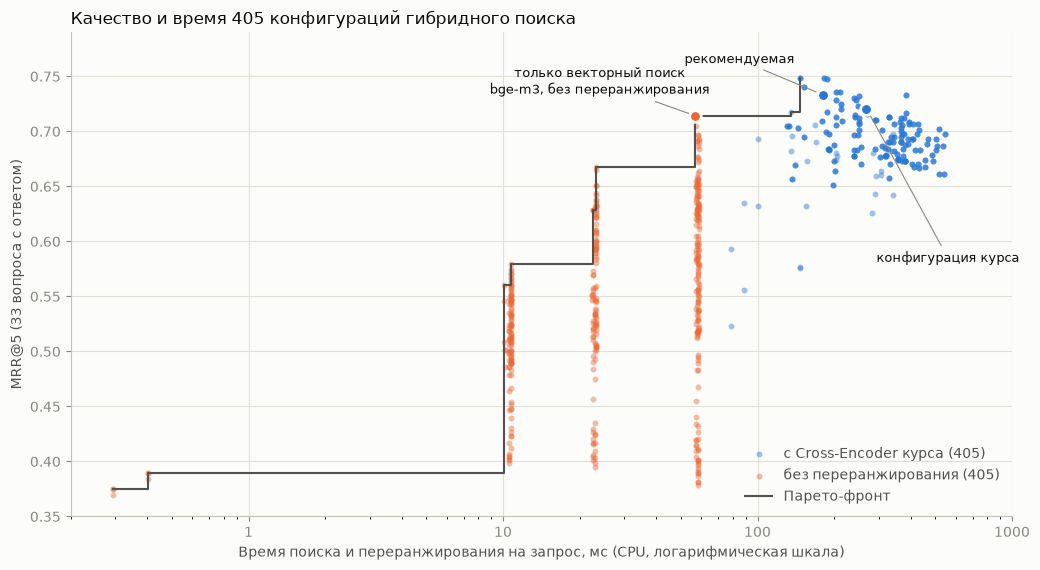

In [42]:
INK, INK2, MUTED, GRIDLINE, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = {"mmarco (курс)": "#2a78d6", "без reranker": "#eb6834"}  # слоты 1 и 2 проверенной палитры

fig, ax = plt.subplots(figsize=(10.5, 5.8), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for rname, color in SERIES.items():
    d = grid[grid.reranker == rname]
    label = "с Cross-Encoder курса" if rname != "без reranker" else "без переранжирования"
    ax.scatter(d[LAT], d["MRR@5"], s=18, color=color, alpha=0.45, linewidths=0, label=f"{label} ({len(d)})")
ax.plot(front[LAT], front["MRR@5"], drawstyle="steps-post", color=INK2, lw=1.5, label="Парето-фронт", zorder=3)
for row, text, xy_text in [(base, "конфигурация курса", (560, 0.585)), (recommended, "рекомендуемая", (85, 0.765)),
                           (fast_no_rerank, "только векторный поиск\nbge-m3, без переранжирования", (24, 0.745))]:
    ax.scatter(row[LAT], row["MRR@5"], s=70, color=SERIES[row["reranker"]], edgecolors=SURFACE, linewidths=2, zorder=4)
    ax.annotate(text, (row[LAT], row["MRR@5"]), xytext=xy_text, fontsize=9, color=INK, ha="center", va="center",
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8, shrinkA=2, shrinkB=5))
ax.set_xscale("log")
ax.set_xlim(0.2, 1000)
ax.set_ylim(0.35, 0.79)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Время поиска и переранжирования на запрос, мс (CPU, логарифмическая шкала)", color=INK2)
ax.set_ylabel("MRR@5 (33 вопроса с ответом)", color=INK2)
ax.set_title("Качество и время 405 конфигураций гибридного поиска", color=INK, loc="left", fontsize=12)
ax.grid(True, color=GRIDLINE, lw=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(AXIS)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="lower right", labelcolor=INK2)
plt.tight_layout()
plt.show()

In [43]:
FRONT_COLS = ["encoder", "tokenizer", "weights", "k_dense", "k_bm25", "reranker", "Hit@5", "MRR@5", LAT]
print("Конфигурации Парето-фронта (по возрастанию времени):")
front[FRONT_COLS].style.hide(axis="index").format({"Hit@5": "{:.3f}", "MRR@5": "{:.3f}", LAT: "{:.1f}",
                                                   "k_dense": "{:.0f}", "k_bm25": "{:.0f}"}, na_rep="—")

Конфигурации Парето-фронта (по возрастанию времени):


encoder,tokenizer,weights,k_dense,k_bm25,reranker,Hit@5,MRR@5,"Время поиска и переранжирования, мс"
—,split,только BM25,—,5,без reranker,0.545,0.375,0.3
—,stem,только BM25,—,5,без reranker,0.697,0.389,0.4
e5-small,—,только векторный,5,—,без reranker,0.758,0.561,10.0
e5-small,split,"0,5 / 0,5",5,20,без reranker,0.727,0.571,10.7
e5-small,stem,"0,5 / 0,5",5,20,без reranker,0.788,0.579,10.8
e5-base + префиксы,—,только векторный,5,—,без reranker,0.788,0.629,22.6
e5-base (курс),stem,"0,5 / 0,5",10,10,без reranker,0.879,0.651,23.1
e5-base + префиксы,stem,"0,5 / 0,5",5,10,без reranker,0.818,0.668,23.2
bge-m3,—,только векторный,5,—,без reranker,0.909,0.714,57.0
e5-large,—,только векторный,5,—,mmarco (курс),0.879,0.717,135.8


In [44]:
rows = {}
for enc in ENCODERS:
    r = find(enc, "stem", k_dense=5, k_bm25=5)
    rows[enc] = {"Recall пула": r["Recall пула"], "Кандидатов (среднее)": r["Кандидатов (среднее)"],
                 "Hit@5": r["Hit@5"], "MRR@5": r["MRR@5"], LAT: r[LAT]}
rows["курс: e5-base, k = 10 / 10, по пробелам"] = {c: base[c] for c in ["Recall пула", "Кандидатов (среднее)", "Hit@5", "MRR@5", LAT]}
print("Полнота пула при k = 5 / 5 (стемминг BM25, переранжирование моделью курса) в сравнении с конфигурацией курса:")
pd.DataFrame(rows).T.astype(float).round(3)

Полнота пула при k = 5 / 5 (стемминг BM25, переранжирование моделью курса) в сравнении с конфигурацией курса:


,Recall пула,Кандидатов (среднее),Hit@5,MRR@5,"Время поиска и переранжирования, мс"
e5-small,0.879,8.194,0.848,0.705,132.619
e5-small + префиксы,0.848,8.056,0.848,0.705,130.737
e5-base (курс),0.939,8.306,0.909,0.748,146.507
e5-base + префиксы,0.909,8.139,0.879,0.703,144.276
e5-large,0.970,8.361,0.939,0.748,182.770
e5-large + префиксы,0.970,8.194,0.939,0.733,180.345
bge-m3,0.939,8.222,0.909,0.710,179.846
"курс: e5-base, k = 10 / 10, по пробелам",0.970,17.250,0.939,0.721,268.077


Рекомендуемая конфигурация выбрана как лучшая из 405 на тех же 33 вопросах, по которым она оценивается. Поэтому оценка её качества может быть завышена: часть преимущества может объясняться особенностями конкретных вопросов. Проверить это позволяют два способа.

1. **Сравнение с конфигурацией курса по тем же вопросам** — разность метрик с бутстреп-интервалом.
2. **Проверка на отложенной половине вопросов.** Правило выбора применяется к случайной половине вопросов (17), а выбранная конфигурация сравнивается с конфигурацией курса на оставшихся 16. Процедура повторяется для 500 случайных разбиений.

In [45]:
def per_q_of(row):
    return PER_Q[(row["id"], row["reranker"])]


rows = []
for metric in ["Hit@5", "MRR@5", "nDCG@5"]:
    rows.append({"Метрика": metric, **paired_diff(per_q_of(recommended)[metric], per_q_of(base)[metric])})
print("Рекомендуемая конфигурация минус конфигурация курса (33 вопроса):")
display(pd.DataFrame(rows).set_index("Метрика").round(3))

keys = [(row["id"], row["reranker"]) for _, row in grid.iterrows()]
MRR_Q = np.array([PER_Q[k]["MRR@5"].values for k in keys])
HIT_Q = np.array([PER_Q[k]["Hit@5"].values for k in keys])
LAT_V = grid[LAT].values
b = grid.index.get_loc(base.name)


def split_half(n_splits=500, seed=0):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_splits):
        perm = rng.permutation(len(ANSWERABLE))
        train, test = perm[:17], perm[17:]
        ok = (HIT_Q[:, train].mean(1) >= HIT_Q[b, train].mean() - 1e-12) & (MRR_Q[:, train].mean(1) >= MRR_Q[b, train].mean() - 1e-12)
        choice = int(np.lexsort((-MRR_Q[:, train].mean(1), np.where(ok, LAT_V, np.inf)))[0])
        out.append({"ΔHit@5": HIT_Q[choice, test].mean() - HIT_Q[b, test].mean(),
                    "ΔMRR@5": MRR_Q[choice, test].mean() - MRR_Q[b, test].mean(),
                    "время / время курса": LAT_V[choice] / LAT_V[b]})
    return pd.DataFrame(out)


halves = split_half()
print("Выбор по 17 вопросам, проверка на 16 отложенных (500 разбиений):")
print(f"  разность Hit@5 на отложенных вопросах: среднее {halves['ΔHit@5'].mean():+.3f}; не хуже курса — "
      f"в {100 * (halves['ΔHit@5'] >= -1e-12).mean():.0f} % разбиений")
print(f"  разность MRR@5 на отложенных вопросах: среднее {halves['ΔMRR@5'].mean():+.3f}; не хуже курса — "
      f"в {100 * (halves['ΔMRR@5'] >= -1e-12).mean():.0f} % разбиений")
print(f"  время выбранной конфигурации относительно курса: медиана {halves['время / время курса'].median():.2f}, "
      f"от {halves['время / время курса'].min():.2f} до {halves['время / время курса'].max():.2f}")

Рекомендуемая конфигурация минус конфигурация курса (33 вопроса):


,разность,95 % ДИ,лучше,хуже
Метрика,,,,
Hit@5,0.000,[+0.000; +0.000],0,0
MRR@5,0.013,[-0.008; +0.045],1,1
nDCG@5,0.025,[-0.007; +0.060],7,4


Выбор по 17 вопросам, проверка на 16 отложенных (500 разбиений):
  разность Hit@5 на отложенных вопросах: среднее -0.099; не хуже курса — в 14 % разбиений
  разность MRR@5 на отложенных вопросах: среднее -0.084; не хуже курса — в 16 % разбиений
  время выбранной конфигурации относительно курса: медиана 0.22, от 0.04 до 0.70


* **Парето-фронт** состоит из трёх участков:
  * только BM25 — менее 1 мс, MRR@5 не выше 0,39;
  * векторный или гибридный поиск без переранжирования — 10–60 мс; лучший результат даёт векторный поиск BGE-M3: MRR@5 0,714 за 57 мс;
  * конфигурации с переранжированием — от 136 мс; максимум MRR@5 0,748 достигается за 147 мс.
* **Конфигурация курса на фронт не попадает:** её качество (MRR@5 0,721 за 268 мс) достижимо быстрее.
* **Рекомендуемая конфигурация** выбрана по правилу: e5-large с префиксами, стемминг BM25, `k` = 5 / 5, Cross-Encoder курса.
  * Hit@5 и полнота пула такие же, как у курса (0,94 и 0,97), MRR@5 — 0,733, время — 180 мс вместо 268 мс (−33 %).
  * Механизм выигрыша виден в таблице полноты пула: крупный кодировщик собирает релевантные фрагменты в первые 5 результатов. Поэтому полнота пула сохраняется при вдвое меньшем числе кандидатов (8,2 вместо 17,3), и время переранжирования сокращается вдвое. У e5-base при `k` = 5 / 5 полнота пула снижается до 0,94, а Hit@5 — до 0,91.
  * Близкая альтернатива с кодировщиком курса — e5-base, стемминг BM25, `k` = 5 / 10: Hit@5 0,94, MRR@5 0,736, 204 мс.
* **Значимость.** Разность качества с курсом статистически не значима: Hit@5 совпадает по каждому вопросу, разность MRR@5 +0,013 (ДИ [−0,008; +0,045]). Выигрыш состоит во времени при сохранении качества на этом наборе вопросов.
* **Устойчивость выбора.** Проверка на отложенных вопросах показывает, что правило «самая быстрая конфигурация не хуже курса» на малой выборке неустойчиво.
  * Применённое к 17 вопросам, оно в 84–86 % разбиений выбирает конфигурацию, которая на оставшихся 16 вопросах хуже курса: в среднем Hit@5 ниже на 0,10, MRR@5 — на 0,08.
  * Причина: при малом числе вопросов многие быстрые конфигурации без переранжирования случайно оказываются не хуже курса.
  * Поэтому рекомендация опирается не только на место в рейтинге, но и на механизм — сохранение полноты пула при меньшем `k`. Окончательный выбор следует подтвердить на расширенном наборе вопросов.

### 3.11. Ответы модели для выбранных конфигураций

Ответы сгенерированы для восьми конфигураций. Они представляют влияние каждого фактора и три точки баланса из п. 3.10: конфигурацию курса, рекомендуемую конфигурацию и лучшую конфигурацию без переранжирования. Каждая конфигурация прогоняется через полный конвейер `get_rag_chain` с настоящими объектами LangChain.

Конфигурации с переранжированием и весами 0,7 / 0,3 или 0,3 / 0,7 отдельно не генерируются. Их пятёрки фрагментов совпадают с конфигурацией курса во всех случаях (п. 3.5), поэтому совпадают и промпты, и ответы.

In [46]:
def as_tuple(row):
    k = lambda v: 10 if pd.isna(v) else int(v)  # для режима с одним ретривером k второго не используется
    return (row["encoder"], row["tokenizer"], WEIGHTS[row["weights"]], k(row["k_dense"]), k(row["k_bm25"]),
            T2_RERANKERS[row["reranker"]])


course = ("e5-base (курс)", "split")
ANSWER_CONFIGS = {
    "курс (0,5 / 0,5, k 10 / 10, reranker)": as_tuple(base),
    "рекомендуемая": as_tuple(recommended),
    "k 20 / 20, reranker": (*course, (0.5, 0.5), 20, 20, CROSS_ENCODER_MODEL),
    "без reranker, 0,7 / 0,3": (*course, (0.7, 0.3), 10, 10, None),
    "без reranker, 0,5 / 0,5": (*course, (0.5, 0.5), 10, 10, None),
    "без reranker, 0,3 / 0,7": (*course, (0.3, 0.7), 10, 10, None),
    "только BM25, без reranker": (*course, (0.0, 1.0), 10, 10, None),
    "лучшая без reranker": as_tuple(fast_no_rerank),
}


def run_task2_answers():
    runs = []
    for name, (enc, tok, w, kd, kb, reranker) in ANSWER_CONFIGS.items():
        chain = get_rag_chain(langchain_retriever(enc, tok, w, kd, kb), reranker, top_k=5)
        for q in QUESTIONS:
            LLM_TRACE.clear()
            out = chain.invoke({"messages": [HumanMessage(content=q["question"])], "timings": {}})
            call = LLM_TRACE[-1]
            runs.append({"config": name, "qid": q["id"], "query": out["transformed_query"],
                         "pool": [d.metadata["chunk_id"] for d in out["raw_docs"]],
                         "top": [d.metadata["chunk_id"] for d in out["documents"]], "answer": out["answer"],
                         "context": format_chunks(out["documents"]), "retrieval_s": out["timings"]["retrieval"],
                         "rerank_s": out["timings"]["rerank"], "generation_s": call.latency_s,
                         "input_tokens": call.input_tokens, "output_tokens": call.output_tokens})
    return runs


t2_runs = stored("task2_runs", run_task2_answers)
t2_judge = stored("task2_judge", lambda: judge_runs(t2_runs))
t2 = pd.DataFrame([{**r, **j, "type": QTYPE[r["qid"]]} for r, j in zip(t2_runs, t2_judge)])
t2 = pd.concat([t2, pd.DataFrame([retrieval_metrics(r["qid"], r["top"]) if r["qid"] in ANSWERABLE else {}
                                  for r in t2_runs])], axis=1)
C_NAMES = list(ANSWER_CONFIGS)
same_as_t1 = (t2[t2.config == C_NAMES[0]].set_index("qid")["answer"]
              == t1[t1.reranker == "mmarco-mMiniLMv2-L12 (курс)"].set_index("qid")["answer"]).all()
print(f"Ответы конфигурации курса совпадают с заданием 1: {same_as_t1}; оценок, не полученных от оценщика: "
      f"{t2['correctness'].isna().sum()}")

t2_table = t2[t2.qid.isin(ANSWERABLE)].groupby("config", sort=False)[["Hit@5", "MRR@5"]].mean()
t2_table = t2_table.join(t2.groupby("config", sort=False).apply(answer_metrics, include_groups=False))
t2_table["Поиск + переранжирование, мс (медиана)"] = 1000 * t2.groupby("config", sort=False).apply(
    lambda g: (g["retrieval_s"] + g["rerank_s"]).median(), include_groups=False)
t2_table["Генерация, с (медиана)"] = t2.groupby("config", sort=False)["generation_s"].median()
t2_table["Токенов промпта (медиана)"] = t2.groupby("config", sort=False)["input_tokens"].median()
t2_table.style.format("{:.3f}").format({"Поиск + переранжирование, мс (медиана)": "{:.0f}",
                                        "Генерация, с (медиана)": "{:.2f}", "Токенов промпта (медиана)": "{:.0f}"})

Ответы конфигурации курса совпадают с заданием 1: True; оценок, не полученных от оценщика: 0


,Hit@5,MRR@5,Верных ответов,Средняя оценка,Обоснованных ответов,"Поиск + переранжирование, мс (медиана)","Генерация, с (медиана)",Токенов промпта (медиана)
config,,,,,,,,
"курс (0,5 / 0,5, k 10 / 10, reranker)",0.939394,0.720707,0.694444,0.791667,0.861111,262,0.61,1014
рекомендуемая,0.939394,0.733333,0.638889,0.777778,0.861111,180,0.64,1012
"k 20 / 20, reranker",0.848485,0.682828,0.638889,0.763889,0.750000,524,0.64,1010
"без reranker, 0,7 / 0,3",0.848485,0.518182,0.666667,0.750000,0.750000,31,0.67,995
"без reranker, 0,5 / 0,5",0.848485,0.513636,0.583333,0.708333,0.722222,23,0.69,1008
"без reranker, 0,3 / 0,7",0.575758,0.416667,0.305556,0.472222,0.555556,32,0.81,975
"только BM25, без reranker",0.545455,0.374747,0.305556,0.444444,0.527778,1,0.70,985
лучшая без reranker,0.909091,0.714141,0.611111,0.750000,0.750000,64,0.70,1034


In [47]:
rows = []
for n in C_NAMES[1:]:
    a = t2[t2.config == n].set_index("qid").loc[[q["id"] for q in QUESTIONS], "correctness"] / 2
    b_ = t2[t2.config == C_NAMES[0]].set_index("qid").loc[[q["id"] for q in QUESTIONS], "correctness"] / 2
    rows.append({"Сравнение": f"{n} − курс", **paired_diff(a, b_)})
print("Разность средней оценки ответа с конфигурацией курса (36 вопросов):")
display(pd.DataFrame(rows).set_index("Сравнение").round(3))

calls = pd.concat([t1[["generation_s", "input_tokens", "output_tokens"]], t2[["generation_s", "input_tokens", "output_tokens"]]])
calls = calls.drop_duplicates()
r_out = np.corrcoef(calls["output_tokens"], calls["generation_s"])[0, 1]
r_in = np.corrcoef(calls["input_tokens"], calls["generation_s"])[0, 1]
print(f"Вызовов генерации (без повторов из кэша): {len(calls)}; время ответа: медиана {calls['generation_s'].median():.2f} с, "
      f"90-й перцентиль {calls['generation_s'].quantile(0.9):.2f} с")
print(f"Корреляция времени генерации с числом токенов ответа: {r_out:.2f}; с числом токенов промпта: {r_in:.2f}")
print(f"Перефразирование запроса (36 вызовов): медиана {np.median(list(REPHRASE_S.values())):.2f} с, "
      f"90-й перцентиль {np.quantile(list(REPHRASE_S.values()), 0.9):.2f} с")

Разность средней оценки ответа с конфигурацией курса (36 вопросов):


,разность,95 % ДИ,лучше,хуже
Сравнение,,,,
рекомендуемая − курс,-0.014,[-0.097; +0.083],3,5
"k 20 / 20, reranker − курс",-0.028,[-0.111; +0.069],3,6
"без reranker, 0,7 / 0,3 − курс",-0.042,[-0.167; +0.069],3,4
"без reranker, 0,5 / 0,5 − курс",-0.083,[-0.208; +0.028],4,7
"без reranker, 0,3 / 0,7 − курс",-0.319,[-0.458; -0.194],1,17
"только BM25, без reranker − курс",-0.347,[-0.472; -0.222],1,19
лучшая без reranker − курс,-0.042,[-0.167; +0.097],5,9


Вызовов генерации (без повторов из кэша): 359; время ответа: медиана 0.69 с, 90-й перцентиль 1.47 с
Корреляция времени генерации с числом токенов ответа: 0.93; с числом токенов промпта: -0.10
Перефразирование запроса (36 вызовов): медиана 0.45 с, 90-й перцентиль 0.63 с


* **Различия между хорошими конфигурациями находятся в пределах погрешности.** Рекомендуемая конфигурация даёт 0,64 верных ответов и среднюю оценку 0,78, курс — 0,69 и 0,79; разность средней оценки −0,014 (ДИ [−0,097; +0,083]). Векторный поиск BGE-M3 без переранжирования даёт 0,61 и 0,75 (разность −0,042, не значима) при времени поиска 64 мс против 262 мс.
* **Значимо хуже только конфигурации с преобладанием BM25:**
  * веса 0,3 / 0,7 без переранжирования — 0,31 верных ответов, разность −0,319;
  * только BM25 — 0,31 верных ответов, разность −0,347.

  Это соответствует падению Hit@5 до 0,58 и 0,55. В этих конфигурациях на вопрос о чистке серебра система дала советы не из документов (оценка 0).
* **Увеличение `k` до 20 / 20** не улучшает ответы (−0,028), снижает Hit@5 до 0,85 и вдвое увеличивает время переранжирования: 524 мс против 262 мс.
* **Веса без переранжирования** влияют на ответы слабее, чем на метрики поиска. Веса 0,7 / 0,3 и 0,5 / 0,5 дают одинаковый Hit@5 (0,85), а их ответы различаются в пределах погрешности: 0,67 и 0,58 верных ответов.
* **Время генерации от конфигурации поиска не зависит:** медиана 0,61–0,81 с при промптах около 1 000 токенов. Оно определяется длиной ответа: корреляция с числом токенов ответа 0,93, с числом токенов промпта −0,10. С учётом перефразирования (0,45 с) поиск и переранжирование составляют от 3 % времени ответа без переранжирования до 17 % в конфигурации курса.

### 3.12. Выводы по заданию 2

1. **Веса `EnsembleRetriever`.**
   * В конвейере курса, где Cross-Encoder переупорядочивает весь пул кандидатов, веса не влияют ни на контекст, ни на ответы: пятёрки совпали в 9 072 из 9 072 сравнений.
   * Без переранжирования неравные веса работают как переключатель приоритета ретриверов. Веса 0,7 / 0,3 и 0,5 / 0,5 равноценны (MRR@5 0,58 и 0,57 в среднем по 126 конфигурациям), а 0,3 / 0,7 заметно хуже (0,47), так как BM25 на русском тексте слабее векторного поиска.
2. **Кодировщик.**
   * В векторном поиске качество растёт с размером модели: MRR@5 от 0,50–0,55 у e5-small до 0,71 у BGE-M3. Префиксы E5, не используемые в курсе, улучшают e5-base и e5-large примерно на 0,07.
   * После переранжирования кодировщик влияет только через полноту пула, и различия сводятся к одному-двум вопросам (MRR@5 0,67–0,72).
   * Цена крупной модели — время запроса (10, 23 и 58 мс) и индексации (7, 17 и 53 с).
3. **Число документов `k`.**
   * `k` определяет число кандидатов, а время переранжирования линейно по нему: 13,7 мс на кандидата на CPU.
   * Увеличение `k` с 10 до 20 не повышает полноту пула, но ухудшает качество (MRR@5 0,721 → 0,683) и вдвое увеличивает время.
   * В конфигурации курса полноту пула определяет `k` векторного поиска; `k` BM25 на неё не влияет.
4. **Токенизация BM25 (дополнительно).** Стемминг и нижний регистр — бесплатное улучшение. Hit@5 BM25 растёт с 0,55 до 0,70, MRR@5 гибрида без переранжирования — с 0,51 до 0,65. С переранжированием эффект нейтрален.
5. **Какие документы выбираются.** Векторный поиск тяготеет к 41-ФЗ и приказу 189н, BM25 — к ЗоЗПП и памяткам. Переранжирование приближает распределение к распределению вопросов. Неравные веса без переранжирования исключают из пятёрки фрагменты, найденные только второстепенным ретривером.
6. **Время.** Время ответа определяется обращениями к языковой модели: 0,45 с на перефразирование и 0,6–0,8 с на генерацию, которая не зависит от параметров поиска. Поиск занимает 10–60 мс, переранжирование — 70–550 мс в зависимости от `k`.
7. **Оптимальный баланс точности и скорости.**
   * **Рекомендуемая конфигурация** — e5-large с префиксами, BM25 со стеммингом, `k` = 5 / 5, веса любые (например, 0,5 / 0,5 как в курсе), Cross-Encoder курса. Она сохраняет Hit@5 и полноту пула конфигурации курса и сокращает время поиска и переранжирования с 268 до 180 мс (−33 %).
   * **Если индексация должна оставаться дешёвой,** близкий результат даёт кодировщик курса со стеммингом и `k` = 5 / 10: 204 мс.
   * **Если важнее всего скорость,** можно отказаться от переранжирования и использовать векторный поиск BGE-M3 с `k` = 5: 57 мс, MRR@5 почти как у курса (0,714 против 0,721), но Hit@5 на один вопрос ниже.
   * Выигрыш во времени детерминирован механизмом — меньшим числом кандидатов. Равенство качества установлено на 33 вопросах и, как показала проверка на отложенных вопросах, требует подтверждения на большем наборе.

---
## 4. Общие выводы

Конвейер Advanced RAG из ноутбука курса применён к русскоязычному корпусу из шести официальных документов (564 фрагмента) и исследован на размеченном наборе из 36 вопросов. Метрики поиска вычислялись по разметке релевантных фрагментов, качество ответов оценивал независимый оценщик, проверенный вручную. Все сравнения сопровождаются 95-процентными бутстреп-интервалами.

1. **Наибольшее влияние на качество контекста оказывает модель переранжирования, а не гиперпараметры гибридного поиска.** Замена Cross-Encoder меняет MRR@5 от 0,23 до 0,73. Все 378 гибридных сочетаний весов, кодировщика, `k` и токенизации при переранжировании моделью курса дают от 0,65 до 0,75.
2. **Модель из условия задания (ms-marco-MiniLM-L-6-v2) для русского корпуса непригодна.** Она хуже, чем отсутствие переранжирования: MRR@5 0,23 против 0,51, верных ответов 28 % против 58 %.
   * Модель курса mmarco-mMiniLMv2-L12 — лучшая по соотношению качества и времени.
   * bge-reranker-v2-m3 равна ей по качеству, но на CPU в 8 раз медленнее.
   * Русскоязычная ruBERT-msmarco уступает обеим мультиязычным моделям.
3. **Веса `EnsembleRetriever` в конвейере курса на результат не влияют**, так как Cross-Encoder переупорядочивает весь пул кандидатов. Настраивать их имеет смысл только без переранжирования. В этом случае неравные веса работают как переключатель приоритета ретриверов, и веса 0,7 / 0,3 или 0,5 / 0,5 предпочтительнее 0,3 / 0,7.
4. **Скорость конвейера с Cross-Encoder определяется числом кандидатов:** 13,7 мс на кандидата на CPU. При более сильном кодировщике (e5-large с префиксами) уменьшение `k` с 10 / 10 до 5 / 5 сокращает время поиска и переранжирования на треть без потери полноты пула. Увеличение `k` до 20 / 20, напротив, удваивает время и ухудшает качество.
5. **В исходном конвейере найдена ошибка промпта перефразирования.** Формулировка «на языке оригинала» приводит к тому, что GigaChat-2 переводит 82 % запросов на английский язык. Hit@5 при этом падает с 0,94 до 0,64. Исправление формулировки и очистка запроса от кавычек устраняют проблему.
6. **Качество ответов ограничено двумя факторами:** наличием релевантного фрагмента в контексте и ошибками генератора. При наличии такого фрагмента полностью верны 69 % ответов, без него — 5 %. Различия между хорошими конфигурациями по качеству ответов на 36 вопросах статистически не значимы.

**Рекомендуемые изменения конвейера курса.**

1. Исправить промпт перефразирования («на языке вопроса пользователя») и очищать запрос от кавычек и служебных префиксов.
2. Сохранить Cross-Encoder mmarco-mMiniLMv2-L12; не использовать англоязычные модели MS MARCO для русских документов.
3. Уменьшить `k` до 5 / 5 при кодировщике e5-large с префиксами. Если кодировщик курса нужно сохранить, использовать `k` = 5 / 10.
4. Добавить префиксы «query: » / «passage: » для моделей E5.
5. Токенизировать BM25 с приведением к нижнему регистру и стеммингом.
6. Оставить веса 0,5 / 0,5: при переранжировании всего пула они не влияют на результат.

**Ограничения.**

* **Малый набор вопросов.** Вопросов с ответом 33, поэтому различия меньше 0,1 по MRR@5 и по средней оценке ответа статистически не значимы. Выбор лучшей из 405 конфигураций на тех же вопросах завышает её оценку (п. 3.10).
* **Составление вопросов.** Вопросы и разметку составил автор работы, знакомый с корпусом. Часть вопросов намеренно перефразирована, но распределение вопросов может отличаться от реальных обращений покупателей.
* **Модели.** Использованы один генератор (GigaChat-2) и один оценщик (`deepseek-flash`). Оценщик проверен вручную на 20 оценках; оценки обоснованности в отдельных случаях мягче ручных.
* **Измерение времени.** Время измерено на CPU одного компьютера. На GPU соотношение затрат на кодировщики и Cross-Encoder иное. Время ответа GigaChat зависит от сети и загрузки сервиса.
* **Разметка привязана к разбиению 800 / 150.** При другом разбиении её нужно пересчитать; шаблоны фактов позволяют сделать это автоматически.
* **Актуальность корпуса.** Памятки 2023 года содержат частично устаревшие нормы, например ссылки на Правила продажи № 2463. Ответы системы корректны относительно корпуса, но не обязательно относительно действующего законодательства.
* **Одиночные вопросы.** Польза перефразирования для диалога с историей сообщений не оценивалась.